In [1]:
# py -m pip install git+https://github.com/pbtamarona/OpenPyTEA
from openpytea.equipment import *
from openpytea.plant import *
from openpytea.analysis import *
from openpytea.plotting import *

C:\Users\pbtamarona\OneDrive - Delft University of Technology\Documents\github-pbtamarona\catalytic_mp\CatalyticMethanePyrolysis\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
#check version
from importlib.metadata import version
print(version("openpytea"))

3.2.2


In [3]:
#Generic settings for plots

import scienceplots
import matplotlib.pyplot as plt
import matplotlib as mpl

mpl.rcParams['axes.grid'] = False

# ticks
mpl.rcParams['xtick.direction'] = 'in'
mpl.rcParams['ytick.direction'] = 'in'

mpl.rcParams['xtick.top'] = True
mpl.rcParams['xtick.bottom'] = True
mpl.rcParams['ytick.left'] = True
mpl.rcParams['ytick.right'] = True

mpl.rcParams['xtick.minor.visible'] = True
mpl.rcParams['ytick.minor.visible'] = True

mpl.rcParams['xtick.major.top'] = True
mpl.rcParams['xtick.major.bottom'] = True
mpl.rcParams['ytick.major.left'] = True
mpl.rcParams['ytick.major.right'] = True

mpl.rcParams['xtick.minor.top'] = True
mpl.rcParams['xtick.minor.bottom'] = True
mpl.rcParams['ytick.minor.left'] = True
mpl.rcParams['ytick.minor.right'] = True

In [4]:
#OPEX Inputs

country, region = 'Netherlands', 'None'
interest_rate, project_lifetime, plant_utilization = 0.09, 20, 0.95
h2_prod = 100_000  # Daily H2 production (kg/day)
tax_rate = 0.258

# Operator hourly rate ($/h)
operator_rate, operator_std, operator_max, operator_min = 39.04, 5.03548, 55, 23.43

# Electricity price ($/kWh)
elecs_price, elecs_std, elecs_max, elecs_min = 0.125, 0.0227273, 0.5, 0.05

# Natural gas price ($/kg)
nat_gas_price, nat_gas_std, nat_gas_max, nat_gas_min = 0.8646, 0.21615, 4.884, 0.30261

# Cooling water price ($/MJ)
cool_water_price, cool_water_std, cool_water_max, cool_water_min = 2.4592e-4, 4.815e-5, 4e-4, 1e-5

# CO2 tax ($/kg CO2)
co2_tax, co2_std, co2_max, co2_min = 0.10201, 0.0258794, 0.19, 0

# Iron catalyst price ($/kg)
cat_price, cat_std, cat_max, cat_min = 4, 1.5, 7, 1

# Catalyst-carbon separation before selling the carbon by-product
sep_efficiency = 0.85  # fraction of iron catalyst removed from the solids
# Separation cost ($/kg of catalyst removed)
sep_cost, sep_cost_std, sep_cost_max, sep_cost_min = 0.5, 0.25, 1, 0

In [5]:
#PSA Sizing

import numpy as np

def calculate_psa_vessel_thickness(vessel_diameter, diameter_threshold=3.5):
    # Minimum practical wall thickness from Towler & Sinnott
    if vessel_diameter <= 1.0:
        minimum_thickness_mm = 5.0
    elif vessel_diameter <= 2.0:
        minimum_thickness_mm = 7.0
    elif vessel_diameter <= 2.5:
        minimum_thickness_mm = 9.0
    elif vessel_diameter <= 3.0:
        minimum_thickness_mm = 10.0
    else:
        minimum_thickness_mm = 12.0

    # Additional thickness margin
    if vessel_diameter <= diameter_threshold:
        extra_thickness_mm = 5.0
    else:
        extra_thickness_mm = 10.0

    return minimum_thickness_mm + extra_thickness_mm


def calculate_psa_vessel_dimensions(adsorbent_mass_per_bed, rho_bulk=795.0, inert_fraction=0.20, aspect_ratio=4.0):
    # Adsorbent volume per bed [m3]
    adsorbent_volume = adsorbent_mass_per_bed / rho_bulk

    # Total internal vessel volume between tangent lines [m3]
    vessel_volume = adsorbent_volume / (1 - inert_fraction)

    # Vessel geometry
    vessel_diameter = (4 * vessel_volume / (np.pi * aspect_ratio)) ** (1 / 3)
    vessel_height = aspect_ratio * vessel_diameter

    return {
        "adsorbent_volume": adsorbent_volume,
        "vessel_volume": vessel_volume,
        "vessel_diameter": vessel_diameter,
        "vessel_height": vessel_height,
        "aspect_ratio": aspect_ratio
    }


def calculate_psa_shell_mass(vessel_diameter, vessel_height, steel_density=7850.0, diameter_threshold=3.5):
    # Wall thickness from vessel diameter
    thickness_mm = calculate_psa_vessel_thickness(vessel_diameter, diameter_threshold=diameter_threshold)
    thickness = thickness_mm / 1000  # m

    # Internal and external diameters
    D_inner = vessel_diameter
    D_outer = D_inner + 2 * thickness

    # Steel volume of cylindrical shell [m3]
    steel_volume = np.pi / 4 * (D_outer**2 - D_inner**2) * vessel_height

    # Shell mass [kg]
    shell_mass = steel_volume * steel_density

    return {
        "wall_thickness_mm": thickness_mm,
        "steel_volume": steel_volume,
        "shell_mass": shell_mass
    }


def calculate_psa_design(df, p_ads_bar=15.0, p_des_bar=1.01, adsorption_time=300.0, bed_loading_fraction=0.85, min_trains=2, n_beds_per_train=4, h2_purity=0.995, product_mass_flow=100_000, rho_bulk=795.0, inert_fraction=0.20, min_aspect_ratio=4.0, max_aspect_ratio=6.0, aspect_ratio_step=0.5, max_diameter=3.5, max_trains=15):


    psa_feed_total = df["PSA Mole Feed [kmol/hr]"].iloc[0]
    ch4_feed_total = df["CH4 Reactor Outlet [kmol/h]"].iloc[0]

    MW_H2 = 2.01588    # kg/kmol
    MW_CH4 = 16.04246  # kg/kmol


    product_mass_total = product_mass_flow / 24  # kg/h

    # Product purity
    MW_product = h2_purity * MW_H2 + (1 - h2_purity) * MW_CH4

    # Total product molar flow and component molar flows [kmol/h]
    total_product_total = product_mass_total / MW_product
    h2_product_total = total_product_total * h2_purity
    ch4_product_total = total_product_total * (1 - h2_purity)

    # CH4 / ZEOLITE 5A ISOTHERM - Towler & Sinnott, Example 16.1
    pressure_data = np.array([0.0, 1.5, 2.5, 4.5, 6.5, 9.0, 12.5, 16.5, 19.5])
    loading_data = np.array([0.0, 0.4, 0.7, 1.0, 1.25, 1.45, 1.60, 1.70, 1.75])  # mmol/g = mol/kg

    bar_to_atm = 0.986923
    valid_design = False
    diameter_fallback = False

    # Number of trains and H/D ratio
    for n_trains in range(min_trains, max_trains + 1):

        # Flow handled by one PSA train
        psa_feed = psa_feed_total / n_trains
        ch4_feed = ch4_feed_total / n_trains
        h2_feed = psa_feed - ch4_feed

        # Product handled by one PSA train
        total_product = total_product_total / n_trains
        h2_product = h2_product_total / n_trains
        ch4_product = ch4_product_total / n_trains


        h2_recovery = h2_product / h2_feed

        # PSA off-gas
        h2_offgas = h2_feed - h2_product
        ch4_offgas = ch4_feed - ch4_product
        total_offgas = h2_offgas + ch4_offgas

        if h2_offgas < 0 or ch4_offgas < 0 or total_offgas <= 0:
            raise ValueError("Calculated PSA outlet flows are not physically consistent.")

        # CH4 mole fractions
        y_ch4_feed = ch4_feed / psa_feed
        y_ch4_offgas = ch4_offgas / total_offgas

        # CH4 partial pressures [atm]
        p_ch4_ads = p_ads_bar * y_ch4_feed * bar_to_atm
        p_ch4_des = p_des_bar * y_ch4_offgas * bar_to_atm

        if p_ch4_ads > pressure_data[-1]:
            raise ValueError("Adsorption CH4 partial pressure exceeds isotherm range.")

        if p_ch4_des > pressure_data[-1]:
            raise ValueError("Desorption CH4 partial pressure exceeds isotherm range.")

        # Equilibrium loadings
        q_ads = np.interp(p_ch4_ads, pressure_data, loading_data)
        q_des = np.interp(p_ch4_des, pressure_data, loading_data)
        working_capacity = q_ads - q_des

        if working_capacity <= 0:
            raise ValueError("PSA working capacity is zero or negative.")

        # ADSORBENT MASS PER BED - Towler Eq. 16.2
        ch4_removed = ch4_feed - ch4_product  # kmol/h
        ch4_removed_mol_s = ch4_removed * 1000 / 3600
        adsorbent_mass_per_bed = ch4_removed_mol_s * adsorption_time / (working_capacity * bed_loading_fraction)

        # Discrete H/D ratios
        aspect_ratios = np.arange(min_aspect_ratio, max_aspect_ratio + aspect_ratio_step / 2, aspect_ratio_step)

        for aspect_ratio in aspect_ratios:
            vessel = calculate_psa_vessel_dimensions(adsorbent_mass_per_bed, rho_bulk=rho_bulk, inert_fraction=inert_fraction, aspect_ratio=aspect_ratio)

            if vessel["vessel_diameter"] <= max_diameter:
                valid_design = True
                break

        # Fallback at max number of trains
        if not valid_design and n_trains == max_trains:
            aspect_ratio = max_aspect_ratio
            vessel = calculate_psa_vessel_dimensions(adsorbent_mass_per_bed, rho_bulk=rho_bulk, inert_fraction=inert_fraction, aspect_ratio=aspect_ratio)

            valid_design = True
            diameter_fallback = True

        if valid_design:
            break

    if not valid_design:
        raise ValueError("No valid PSA configuration could be determined.")

    # Total number of vessels and adsorbent mass
    n_vessels = n_trains * n_beds_per_train
    total_adsorbent_mass = adsorbent_mass_per_bed * n_vessels

    # STEEL VOLUME AND SHELL MASS
    shell = calculate_psa_shell_mass(vessel["vessel_diameter"], vessel["vessel_height"], diameter_threshold=max_diameter)
    total_shell_mass = shell["shell_mass"] * n_vessels

    return {
        "h2_recovery": h2_recovery,
        "total_product_molar_flow": total_product_total,
        "h2_product_molar_flow": h2_product_total,
        "ch4_product_molar_flow": ch4_product_total,
        "adsorbent_mass_per_bed": adsorbent_mass_per_bed,
        "total_adsorbent_mass": total_adsorbent_mass,
        "vessel_volume": vessel["vessel_volume"],
        "vessel_diameter": vessel["vessel_diameter"],
        "vessel_height": vessel["vessel_height"],
        "aspect_ratio": vessel["aspect_ratio"],
        "wall_thickness_mm": shell["wall_thickness_mm"],
        "steel_volume_per_vessel": shell["steel_volume"],
        "shell_mass_per_vessel": shell["shell_mass"],
        "total_shell_mass": total_shell_mass,
        "n_trains": n_trains,
        "n_beds_per_train": n_beds_per_train,
        "n_vessels": n_vessels,
        "diameter_fallback": diameter_fallback
    }

In [6]:
#CAPEX and OPEX Setup
def run_tea_pfr(csv_path):

    df = pd.read_csv(csv_path)

    # START OF EQUIPMENT DEFINITION
    comp_1_pwr = df["Comp-1 Power [kW]"].iloc[0]  # kW
    comp_2_pwr = df["Comp-2 Power [kW]"].iloc[0]  # kW
    comp_3_pwr = df["Comp-3 Power [kW]"].iloc[0]  # kW
    comp_4_pwr = df["Comp-4 Power [kW]"].iloc[0]  # kW

    hx1_area = df["HeatX-1 Area [m2]"].iloc[0]
    hx2_area = df["HeatX-2 Area [m2]"].iloc[0]
    hx3_area = df["HeatX-3 Area [m2]"].iloc[0]

    cooler1_area = df["Cooler-1 Area [m2]"].iloc[0]
    cooler2_area = df["Cooler-2 Area [m2]"].iloc[0]
    cooler3_area = df["Cooler-3 Area [m2]"].iloc[0]
    cooler4_area = df["Cooler-4 Area [m2]"].iloc[0]

    reactor_volume = df["Reactor Volume [m3]"].iloc[0]  # m3

    total_heating = (df["Heater-1 Duty [MW]"].iloc[0] + df["Heater-2 Duty [MW]"].iloc[0] + df["Reactor Duty [MW]"].iloc[0]) * 1000  # kW

    cyclone_rate = df["Cyclone Volumetric [m3/s]"].iloc[0]

    co2_flow = df["CO2 Emission [kg/h]"].iloc[0]  # Without/before CCS
    co2_flow_ccs = df["CO2 with CCS [kg/h]"].iloc[0]  # Remaining CO2 after storage

    pump_flow = df["Pump Flow [L/s]"].iloc[0]
    turbine_power = df["Turb-1 Power [kW]"].iloc[0]  # kW

    # Compressors and motors

    elec_mecc_eff = 0.9

    mtr_1_pwr, mtr_2_pwr, mtr_3_pwr, mtr_4_pwr = comp_1_pwr / (elec_mecc_eff), comp_2_pwr / (elec_mecc_eff), comp_3_pwr / (elec_mecc_eff), comp_4_pwr / (elec_mecc_eff)

    # Seider correlation: input in hp; electric motor included
    comp_1 = Equipment('COMP-1', comp_1_pwr / 0.7457, "Fluids", "Compressors, fans, & blowers", "Centrifugal (turbo) blower", "Carbon steel")

    # Towler correlation: driver power in kW
    comp_2 = Equipment('COMP-2', comp_2_pwr, "Fluids", "Compressors, fans, & blowers", "Compressor, centrifugal", "Carbon steel")

    # Seider correlation: input in hp; electric motor included
    comp_3 = Equipment('COMP-3', comp_3_pwr / 0.7457, "Fluids", "Compressors, fans, & blowers", "Centrifugal (turbo) blower", "Carbon steel")

    # Manzolini correlation: electric power in MWe; motor included
    comp_4 = Equipment('COMP-4', mtr_4_pwr / 1000, "Fluids", "Compressors, fans, & blowers", "CO2 compressor", "316 stainless steel")

    #Correlation requires shaft power, here assumed in direct connection with shaft of the compressor so with negligible mechanical losses of coupling. There will be losses in electrical requirement
    mtr_2 = Equipment('MTR-2', comp_2_pwr, "Electrical", "Motors & generators", "Explosion-proof motor", "Carbon steel")

    #Heat Exchangers

    hx_1 = Equipment('HX-1', hx1_area, "Fluids", "Heat exchangers", "Floating head shell & tube", "Inconel")

    # max() retained because the lower limit is 10 m2
    hx_2 = Equipment('HX-2', max(hx2_area, 10), "Fluids", "Heat exchangers", "Fixed tube", "Carbon steel")

    hx_3 = Equipment('HX-3', hx3_area, "Fluids", "Heat exchangers", "U-tube shell & tube", "Inconel")

    #Coolers

    cooler_1 = Equipment('COOLER-1', cooler1_area, "Fluids", "Heat exchangers", "Fixed tube", "Carbon steel")

    cooler_2 = Equipment('COOLER-2', cooler2_area, "Fluids", "Heat exchangers", "Fixed tube", "Carbon steel")

    cooler_3 = Equipment('COOLER-3', cooler3_area, "Fluids", "Heat exchangers", "Fixed tube", "316 stainless steel")

    cooler_4 = Equipment('COOLER-4', cooler4_area, "Fluids", "Heat exchangers", "Floating head shell & tube", "316 stainless steel")

    #Reactor

    FeMP_PFR_reactor = Equipment('FeMP_PFR_reactor', reactor_volume, "Mixed", "Reactors", "Indirect fluidized-bed", "Inconel")

    #Other Equipment

    furnace = Equipment('FURNACE', (total_heating) / 0.85, "Fluids", "Boilers, heaters, & furnaces", "Nonreactive fired heater", "Inconel")

    cyclone = Equipment('CYCLONE', cyclone_rate, "Mixed", "Dust collectors", "Gas multi-cyclone", "Inconel")

    co2_capture = Equipment('CO2-capture', (co2_flow - co2_flow_ccs) / 3600, "Fluids", "CO2 capture", "MEA CCS technology", "316 stainless steel")

    pump = Equipment('PUMP', pump_flow, "Fluids", "Pumps", "Single-stage centrifugal", "Carbon steel")

    turbine = Equipment('TURBINE', turbine_power * -1, "Fluids", "Turbines", "Condensing steam turbine", "Inconel")  #negative in csv

    generator = Equipment('GENERATOR', turbine_power * -1, "Electrical", "Motors & generators", "Totally enclosed motor", "Carbon steel")

    # PSA
    psa_design = calculate_psa_design(df, p_ads_bar=15.0, p_des_bar=1.01, min_trains=2, n_beds_per_train=4)

    psa_shell_mass = psa_design["shell_mass_per_vessel"]
    psa_adsorbent_mass_total = psa_design["total_adsorbent_mass"]
    n_psa_vessels = psa_design["n_vessels"]

    # PSA vessels
    psa_vessel = Equipment(name="PSA-VESSEL", param=psa_shell_mass, process_type="Fluids", category="Pressure vessels", type="Vertical CS", material="Carbon steel", num_units=n_psa_vessels)

    # Zeolite 5A
    psa_adsorbent_volume_total_m3 = psa_adsorbent_mass_total / 795.0
    psa_adsorbent_volume_total_ft3 = psa_adsorbent_volume_total_m3 * 35.3146667

    psa_zeolite = Equipment(name="PSA-ZEOLITE-5A", param=psa_adsorbent_volume_total_ft3, process_type="Solids", category="Packings & adsorbents", type="Molecular sieves")

    # Complete PSA unit
    psa = CompositeEquipment(name="PSA", process_type="Fluids", components=[psa_vessel, psa_zeolite], category="Adsorption", type="Pressure-swing adsorber")

    FeMP_PFR_equipment = [
     comp_1,
     comp_2, mtr_2,
     comp_3,
     comp_4,
     hx_1, hx_2, hx_3,
     cooler_1, cooler_2, cooler_3, cooler_4,
     FeMP_PFR_reactor,
     furnace, cyclone, turbine, pump, co2_capture, psa, generator
    ]


    #START OF PLANT
    methane_feed = df["CH4 Feed [kg/h]"].iloc[0]  #kg/h
    fuel_feed = df["Fuel Feed [kg/h]"].iloc[0]
    coolwater_total = df["Cool Water Total [kJ/s]"].iloc[0]
    co2_flow = df["CO2 Emission [kg/h]"].iloc[0] #without/before CCS
    co2_flow_ccs = df["CO2 with CCS [kg/h]"].iloc[0]  #remaining co2 after storage
    carbon_prod = df["C Prod [kg/h]"].iloc[0]
    catalyst_flow = df["Cat Rate [kg/h]"].iloc[0]
    # Separation of the iron catalyst from the carbon before selling
    catalyst_removed = sep_efficiency * catalyst_flow  # kg/h of catalyst removed
    carbon_rich_flow = carbon_prod + catalyst_flow - catalyst_removed  # kg/h of carbon-rich solids
    ch4_reactor_in = df["CH4 Reactor Feed [kmol/h]"].iloc[0]
    ch4_reactor_out = df["CH4 Reactor Outlet [kmol/h]"].iloc[0]

    residence_time = df["Cat Res. Time [s]"].iloc[0]
    deactivation_factor = df["Reactor Deactivation"].iloc[0]

    mecc_elec_eff = 0.9  #turbine recovery efficiency
    react_heat_eff = 0.9  #electric heating for reactor

    # Configuration for the FeMP_Methane plant
    config = {'plant_name': 'PFR',
              'process_type': 'Mixed',   # Since there are both fluids and solids involved
              'country': country, 'region': region,
              'equipment': FeMP_PFR_equipment,
              'interest_rate': interest_rate,
              'tax_rate': tax_rate,
              'project_lifetime': project_lifetime,
              'plant_utilization': plant_utilization,
              'operator_hourly_rate': {
                  'rate': operator_rate, 'std': operator_std, 'max': operator_max, 'min': operator_min
                  },
              'plant_products': {
                  'hydrogen': {
                      'production': h2_prod, # Daily production in kg/day
                      'price': 5.0                  # Price in USD/unit
                  },
                  'carbon': {
                      'production': carbon_rich_flow*0.5*24,  'price': 1.5, 'std': 0.5, 'max': 6, 'min': 0 # Daily production in kg/day
                  }
                },
              'variable_opex_inputs': {
                  'electricity': {
                      'consumption': (mtr_1_pwr + mtr_2_pwr + mtr_3_pwr + mtr_4_pwr + turbine_power * mecc_elec_eff)*24, 'price': elecs_price, 'std': elecs_std, 'max': elecs_max, 'min': elecs_min #kWday, turbine power already negative
                  },
                  'methane_feed':{
                      'consumption': (methane_feed + fuel_feed)*24, 'price': nat_gas_price, 'std': nat_gas_std, 'max': nat_gas_max, 'min': nat_gas_min #kg/day
                  },
                  'catalyst_feed':{
                      'consumption': catalyst_flow*24, 'price': cat_price, 'std': cat_std, 'max': cat_max, 'min': cat_min #kg/day
                  },
                  'cooling_water': {
                      'consumption': (coolwater_total)*3600 * 24/1000, 'price': cool_water_price, 'std': cool_water_std, 'max': cool_water_max, 'min': cool_water_min
                  }, #MJ/day
                  'CO2_tax': {
                      'consumption': (co2_flow_ccs)*24, 'price': co2_tax, 'std': co2_std, 'max': co2_max, 'min': co2_min #kg/h
                  },
                  'catalyst_separation': {
                      'consumption': catalyst_removed*24, 'price': sep_cost, 'std': sep_cost_std, 'max': sep_cost_max, 'min': sep_cost_min #kg/day of catalyst removed
                  },

                  'carbon_disposal_fee': {
                      'consumption': carbon_rich_flow*0.5*24, 'price': 0.5, 'std': 0.5/2, 'max': 1, 'min': 0 #kg/day
                  },
                },
    }

    FeMP_PFR_plant = Plant(config)

    ch4_conversion = (ch4_reactor_in - ch4_reactor_out) * 100 / ch4_reactor_in

    #START OF ECONOMIC ANALYSIS
    capex = FeMP_PFR_plant.calculate_fixed_capital(print_results=False)
    isbl = FeMP_PFR_plant.calculate_isbl(print_results=False)
    fixed_opex = FeMP_PFR_plant.calculate_fixed_opex(print_results=False)
    variable_opex = FeMP_PFR_plant.calculate_variable_opex(print_results=False)
    revenue = FeMP_PFR_plant.calculate_revenue(print_results=False)
    cash_flow_styler = FeMP_PFR_plant.calculate_cash_flow(print_results=True)
    cash_flow_df = cash_flow_styler.data
    npv = FeMP_PFR_plant.calculate_npv(print_results=False)
    pbt = FeMP_PFR_plant.calculate_simple_payback_time(print_results=False)
    pbt_add = FeMP_PFR_plant.calculate_simple_payback_time(print_results=False, additional_capex=True)
    lcoh_PFR = FeMP_PFR_plant.calculate_levelized_cost(print_results=False)
    roi = FeMP_PFR_plant.calculate_roi(print_results=False)
    roi_add = FeMP_PFR_plant.calculate_roi(print_results=False, additional_capex=True)
    irr = FeMP_PFR_plant.calculate_irr(print_results=False)

    return {
     "plant_pfr": FeMP_PFR_plant,
     "capex_pfr":capex,
     "isbl_pfr": isbl,
     "fixed_opex_pfr": fixed_opex,
     "variable_opex_pfr": variable_opex,
     "revenue_pfr": revenue,
     "cash_flow_pfr": cash_flow_df,
     "npv_pfr": npv,
     "pbt_pfr": pbt,
     "pbt_add_pfr": pbt_add,
     "lcoh_pfr": lcoh_PFR,
     "roi_pfr": roi,
     "roi_add_pfr": roi_add,
     "irr_pfr": irr,
     "catalyst_rate_pfr":  catalyst_flow,
     "deac_factor_pfr": deactivation_factor,
     "conversion_pfr": ch4_conversion,
     "res_time_pfr": residence_time
}


In [7]:
#CAPEX and OPEX Setup similar to PFR
def run_tea_cstr(csv_path):

    df = pd.read_csv(csv_path)

    # START OF EQUIPMENT DEFINITION
    comp_1_pwr = df["Comp-1 Power [kW]"].iloc[0]  # kW
    comp_2_pwr = df["Comp-2 Power [kW]"].iloc[0]  # kW
    comp_3_pwr = df["Comp-3 Power [kW]"].iloc[0]  # kW
    comp_4_pwr = df["Comp-4 Power [kW]"].iloc[0]  # kW

    hx1_area = df["HeatX-1 Area [m2]"].iloc[0]
    hx2_area = df["HeatX-2 Area [m2]"].iloc[0]
    hx3_area = df["HeatX-3 Area [m2]"].iloc[0]

    cooler1_area = df["Cooler-1 Area [m2]"].iloc[0]
    cooler2_area = df["Cooler-2 Area [m2]"].iloc[0]
    cooler3_area = df["Cooler-3 Area [m2]"].iloc[0]
    cooler4_area = df["Cooler-4 Area [m2]"].iloc[0]

    reactor_volume = df["Reactor Volume [m3]"].iloc[0]  # m3

    total_heating = (df["Heater-1 Duty [MW]"].iloc[0] + df["Heater-2 Duty [MW]"].iloc[0] + df["Reactor Duty [MW]"].iloc[0]) * 1000  # kW

    cyclone_rate = df["Cyclone Volumetric [m3/s]"].iloc[0]

    co2_flow = df["CO2 Emission [kg/h]"].iloc[0]  # Without/before CCS
    co2_flow_ccs = df["CO2 with CCS [kg/h]"].iloc[0]  # Remaining CO2 after storage

    pump_flow = df["Pump Flow [L/s]"].iloc[0]
    turbine_power = df["Turb-1 Power [kW]"].iloc[0]  # kW

    elec_mecc_eff = 0.9

    mtr_1_pwr, mtr_2_pwr, mtr_3_pwr, mtr_4_pwr = comp_1_pwr / (elec_mecc_eff), comp_2_pwr / (elec_mecc_eff), comp_3_pwr / (elec_mecc_eff), comp_4_pwr / (elec_mecc_eff)


    # Seider correlation: input in hp; electric motor included
    comp_1 = Equipment('COMP-1', comp_1_pwr / 0.7457, "Fluids", "Compressors, fans, & blowers", "Centrifugal (turbo) blower", "Carbon steel")

    # Towler correlation: driver power in kW
    comp_2 = Equipment('COMP-2', comp_2_pwr, "Fluids", "Compressors, fans, & blowers", "Compressor, centrifugal", "Carbon steel")

    # Seider correlation: input in hp; electric motor included
    comp_3 = Equipment('COMP-3', comp_3_pwr / 0.7457, "Fluids", "Compressors, fans, & blowers", "Centrifugal (turbo) blower", "Carbon steel")

    # Manzolini correlation: electric power in MWe with motor
    comp_4 = Equipment('COMP-4', mtr_4_pwr / 1000, "Fluids", "Compressors, fans, & blowers", "CO2 compressor", "316 stainless steel")

    #Correlation requires shaft power, here assumed in direct connection with shaft of the compressor so with negligible mechanical losses of coupling. There will be losses in electrical requirement
    mtr_2 = Equipment('MTR-2', comp_2_pwr, "Electrical", "Motors & generators", "Explosion-proof motor", "Carbon steel")

    hx_1 = Equipment('HX-1', hx1_area, "Fluids", "Heat exchangers", "Floating head shell & tube", "Inconel")


    hx_2 = Equipment('HX-2', max(hx2_area, 10), "Fluids", "Heat exchangers", "Fixed tube", "Carbon steel")

    hx_3 = Equipment('HX-3', hx3_area, "Fluids", "Heat exchangers", "U-tube shell & tube", "Inconel")


    cooler_1 = Equipment('COOLER-1', cooler1_area, "Fluids", "Heat exchangers", "Fixed tube", "Carbon steel")

    cooler_2 = Equipment('COOLER-2', cooler2_area, "Fluids", "Heat exchangers", "Fixed tube", "Carbon steel")

    cooler_3 = Equipment('COOLER-3', cooler3_area, "Fluids", "Heat exchangers", "Fixed tube", "316 stainless steel")

    cooler_4 = Equipment('COOLER-4', cooler4_area, "Fluids", "Heat exchangers", "Floating head shell & tube", "316 stainless steel")


    FeMP_CSTR_reactor = Equipment('FeMP_CSTR_reactor', reactor_volume, "Mixed", "Reactors", "Indirect fluidized-bed", "Inconel")


    furnace = Equipment('FURNACE', (total_heating) / 0.85, "Fluids", "Boilers, heaters, & furnaces", "Nonreactive fired heater", "Inconel")

    cyclone = Equipment('CYCLONE', cyclone_rate, "Mixed", "Dust collectors", "Gas multi-cyclone", "Inconel")

    co2_capture = Equipment('CO2-capture', (co2_flow - co2_flow_ccs) / 3600, "Fluids", "CO2 capture", "MEA CCS technology", "316 stainless steel")

    pump = Equipment('PUMP', pump_flow, "Fluids", "Pumps", "Single-stage centrifugal", "Carbon steel")

    turbine = Equipment('TURBINE', turbine_power * -1, "Fluids", "Turbines", "Condensing steam turbine", "Inconel")

    generator = Equipment('GENERATOR', turbine_power * -1, "Electrical", "Motors & generators", "Totally enclosed motor", "Carbon steel")

    # PSA
    psa_design = calculate_psa_design(df, p_ads_bar=15.0, p_des_bar=1.01, min_trains=2, n_beds_per_train=4)

    psa_shell_mass = psa_design["shell_mass_per_vessel"]
    psa_adsorbent_mass_total = psa_design["total_adsorbent_mass"]
    n_psa_vessels = psa_design["n_vessels"]

    # PSA vessels
    psa_vessel = Equipment(name="PSA-VESSEL", param=psa_shell_mass, process_type="Fluids", category="Pressure vessels", type="Vertical CS", material="Carbon steel", num_units=n_psa_vessels)

    # Zeolite 5A
    psa_adsorbent_volume_total_m3 = psa_adsorbent_mass_total / 795.0
    psa_adsorbent_volume_total_ft3 = psa_adsorbent_volume_total_m3 * 35.3146667

    psa_zeolite = Equipment(name="PSA-ZEOLITE-5A", param=psa_adsorbent_volume_total_ft3, process_type="Solids", category="Packings & adsorbents", type="Molecular sieves")

    # Complete PSA unit
    psa = CompositeEquipment(name="PSA", process_type="Fluids", components=[psa_vessel, psa_zeolite], category="Adsorption", type="Pressure-swing adsorber")

    FeMP_CSTR_equipment = [
     comp_1,
     comp_2, mtr_2,
     comp_3,
     comp_4,
     hx_1, hx_2, hx_3,
     cooler_1, cooler_2, cooler_3, cooler_4,
     FeMP_CSTR_reactor,
     furnace, cyclone, turbine, pump, co2_capture, psa, generator
    ]


    #START OF PLANT
    methane_feed = df["CH4 Feed [kg/h]"].iloc[0]  #kg/h
    fuel_feed = df["Fuel Feed [kg/h]"].iloc[0]
    coolwater_total = df["Cool Water Total [kJ/s]"].iloc[0]
    co2_flow = df["CO2 Emission [kg/h]"].iloc[0] #without/before CCS
    co2_flow_ccs = df["CO2 with CCS [kg/h]"].iloc[0]  #remaining co2 after storage
    carbon_prod = df["C Prod [kg/h]"].iloc[0]
    catalyst_flow = df["Cat Rate [kg/h]"].iloc[0]
    # Separation of the iron catalyst from the carbon before selling
    catalyst_removed = sep_efficiency * catalyst_flow  # kg/h of catalyst removed
    carbon_rich_flow = carbon_prod + catalyst_flow - catalyst_removed  # kg/h of carbon-rich solids
    ch4_reactor_in = df["CH4 Reactor Feed [kmol/h]"].iloc[0]
    ch4_reactor_out = df["CH4 Reactor Outlet [kmol/h]"].iloc[0]

    residence_time = df["Cat Res. Time [s]"].iloc[0]
    deactivation_factor = df["Reactor Deactivation"].iloc[0]

    mecc_elec_eff = 0.9  #turbine electric recovery
    react_heat_eff = 0.9  #electric heating for reactor

    # Configuration for the FeMP_Methane plant
    config = {'plant_name': 'CSTR',
              'process_type': 'Mixed',
              'country': country, 'region': region,
              'equipment': FeMP_CSTR_equipment,
              'interest_rate': interest_rate,
              'tax_rate': tax_rate,
              'project_lifetime': project_lifetime,
              'plant_utilization': plant_utilization,
              'operator_hourly_rate': {
                  'rate': operator_rate, 'std': operator_std, 'max': operator_max, 'min': operator_min
                  },
              'plant_products': {
                  'hydrogen': {
                      'production': h2_prod, # Daily production in kg/day,
                      'price': 5.0                  # Price in USD/unit
                  },
                  'carbon': {
                      'production': carbon_rich_flow*0.5*24,  'price': 1.5, 'std': 0.5, 'max': 6, 'min': 0 # Daily production in kg/day
                  }
                },
              'variable_opex_inputs': {
                  'electricity': {
                      'consumption': (mtr_1_pwr + mtr_2_pwr + mtr_3_pwr + mtr_4_pwr + turbine_power * mecc_elec_eff)*24, 'price': elecs_price, 'std': elecs_std, 'max': elecs_max, 'min': elecs_min #kWday, turbine power already negative
                  },
                  'methane_feed':{
                      'consumption': (methane_feed + fuel_feed)*24, 'price': nat_gas_price, 'std': nat_gas_std, 'max': nat_gas_max, 'min': nat_gas_min #kg/day
                  },
                  'catalyst_feed':{
                      'consumption': catalyst_flow*24, 'price': cat_price, 'std': cat_std, 'max': cat_max, 'min': cat_min #kg/day
                  },
                  'cooling_water': {
                      'consumption': (coolwater_total)*3600*24/1000, 'price': cool_water_price, 'std': cool_water_std, 'max': cool_water_max, 'min': cool_water_min
                  }, #transform in MJ/day
                  'CO2_tax': {
                      'consumption': (co2_flow_ccs)*24, 'price': co2_tax, 'std': co2_std, 'max': co2_max, 'min': co2_min #kg/h
                  },
                  'catalyst_separation': {
                      'consumption': catalyst_removed*24, 'price': sep_cost, 'std': sep_cost_std, 'max': sep_cost_max, 'min': sep_cost_min #kg/day of catalyst removed
                  },

                  'carbon_disposal_fee': {
                      'consumption': carbon_rich_flow*0.5*24, 'price': 0.5, 'std': 0.5/2, 'max': 1, 'min': 0 #kg/day
                  },
                },
    }

    FeMP_CSTR_plant = Plant(config)    # Create the process plant object. Here we name it FeMP_CSTR_plant. End of configuration!

    ch4_conversion = (ch4_reactor_in - ch4_reactor_out) * 100 / ch4_reactor_in

    #START OF ECONOMIC ANALYSIS
    #define economic variables
    capex = FeMP_CSTR_plant.calculate_fixed_capital(print_results=False)
    isbl = FeMP_CSTR_plant.calculate_isbl(print_results=False)
    fixed_opex = FeMP_CSTR_plant.calculate_fixed_opex(print_results=False)
    variable_opex = FeMP_CSTR_plant.calculate_variable_opex(print_results=False)
    revenue = FeMP_CSTR_plant.calculate_revenue(print_results=False)
    cash_flow_styler = FeMP_CSTR_plant.calculate_cash_flow(print_results=True)
    cash_flow_df = cash_flow_styler.data
    npv = FeMP_CSTR_plant.calculate_npv(print_results=False)
    pbt = FeMP_CSTR_plant.calculate_simple_payback_time(print_results=False)
    pbt_add = FeMP_CSTR_plant.calculate_simple_payback_time(print_results=False, additional_capex=True)
    lcoh = FeMP_CSTR_plant.calculate_levelized_cost(print_results=False)
    roi = FeMP_CSTR_plant.calculate_roi(print_results=False)
    roi_add = FeMP_CSTR_plant.calculate_roi(print_results=False, additional_capex=True)
    irr = FeMP_CSTR_plant.calculate_irr(print_results=False)

    return {
     "plant_cstr": FeMP_CSTR_plant,
     "capex_cstr":capex,
     "isbl_cstr": isbl,
     "fixed_opex_cstr": fixed_opex,
     "variable_opex_cstr": variable_opex,
     "revenue_cstr": revenue,
     "cash_flow_cstr": cash_flow_df,
     "npv_cstr": npv,
     "pbt_cstr": pbt,
     "pbt_add_cstr": pbt_add,
     "lcoh_cstr": lcoh,
     "roi_cstr": roi,
     "roi_add_cstr": roi_add,
     "irr_cstr": irr,
     "catalyst_rate_cstr":  catalyst_flow,
     "deac_factor_cstr": deactivation_factor,
     "conversion_cstr": ch4_conversion,
     "res_time_cstr": residence_time
}

In [8]:
#BASELINE SCENARIO: T = 725°C, w = 10000kg, a = 0.2

In [9]:
#Changing Temperature; Fixed w (10000kg) and a (0.2)
#CH4
#PFR case
csv_files_PFR_Tchange_DA02_W10000 = {
    700: "../Results_Simulations/sim-PFR-100TPD-ch4-t700-p1.07-c10000-da0.2-psa15.csv",
    725: "../Results_Simulations/sim-PFR-100TPD-ch4-t725-p1.07-c10000-da0.2-psa15.csv",
    750: "../Results_Simulations/sim-PFR-100TPD-ch4-t750-p1.07-c10000-da0.2-psa15.csv",
    775: "../Results_Simulations/sim-PFR-100TPD-ch4-t775-p1.07-c10000-da0.2-psa15.csv",
    800: "../Results_Simulations/sim-PFR-100TPD-ch4-t800-p1.07-c10000-da0.2-psa15.csv",
    825: "../Results_Simulations/sim-PFR-100TPD-ch4-t825-p1.07-c10000-da0.2-psa15.csv",
    850: "../Results_Simulations/sim-PFR-100TPD-ch4-t850-p1.07-c10000-da0.2-psa15.csv",
}

# CSTR case
csv_files_CSTR_Tchange_DA02_W10000 = {
    700: "../Results_Simulations/sim-CSTR-100TPD-ch4-t700-p1.07-c10000-da0.2-psa15.csv",
    725: "../Results_Simulations/sim-CSTR-100TPD-ch4-t725-p1.07-c10000-da0.2-psa15.csv",
    750: "../Results_Simulations/sim-CSTR-100TPD-ch4-t750-p1.07-c10000-da0.2-psa15.csv",
    775: "../Results_Simulations/sim-CSTR-100TPD-ch4-t775-p1.07-c10000-da0.2-psa15.csv",
    800: "../Results_Simulations/sim-CSTR-100TPD-ch4-t800-p1.07-c10000-da0.2-psa15.csv",
    825: "../Results_Simulations/sim-CSTR-100TPD-ch4-t825-p1.07-c10000-da0.2-psa15.csv",
    850: "../Results_Simulations/sim-CSTR-100TPD-ch4-t850-p1.07-c10000-da0.2-psa15.csv",
}

In [10]:
#Changing catalyst amount; Fixed T (725°C) and a (0.2)
# PFR
csv_files_PFR_T725_DA02_Wchange = {
    5000: "../Results_Simulations/sim-PFR-100TPD-ch4-t725-p1.07-c5000-da0.2-psa15.csv",
    7500: "../Results_Simulations/sim-PFR-100TPD-ch4-t725-p1.07-c7500-da0.2-psa15.csv",
    10000: "../Results_Simulations/sim-PFR-100TPD-ch4-t725-p1.07-c10000-da0.2-psa15.csv",
    12500: "../Results_Simulations/sim-PFR-100TPD-ch4-t725-p1.07-c12500-da0.2-psa15.csv",
    15000: "../Results_Simulations/sim-PFR-100TPD-ch4-t725-p1.07-c15000-da0.2-psa15.csv",
}

# CSTR
csv_files_CSTR_T725_DA02_Wchange = {
    5000: "../Results_Simulations/sim-CSTR-100TPD-ch4-t725-p1.07-c5000-da0.2-psa15.csv",
    7500: "../Results_Simulations/sim-CSTR-100TPD-ch4-t725-p1.07-c7500-da0.2-psa15.csv",
    10000: "../Results_Simulations/sim-CSTR-100TPD-ch4-t725-p1.07-c10000-da0.2-psa15.csv",
    12500: "../Results_Simulations/sim-CSTR-100TPD-ch4-t725-p1.07-c12500-da0.2-psa15.csv",
    15000: "../Results_Simulations/sim-CSTR-100TPD-ch4-t725-p1.07-c15000-da0.2-psa15.csv",
}

In [11]:
#Changing catalyst deactivation; Fixed T (725°C) and w (10000kg)
# PFR
csv_files_PFR_T725_W10000_DAchange = {
    0.15: "../Results_Simulations/sim-PFR-100TPD-ch4-t725-p1.07-c10000-da0.15-psa15.csv",
    0.2: "../Results_Simulations/sim-PFR-100TPD-ch4-t725-p1.07-c10000-da0.2-psa15.csv",
    0.25: "../Results_Simulations/sim-PFR-100TPD-ch4-t725-p1.07-c10000-da0.25-psa15.csv",
    0.3: "../Results_Simulations/sim-PFR-100TPD-ch4-t725-p1.07-c10000-da0.3-psa15.csv",
    0.35: "../Results_Simulations/sim-PFR-100TPD-ch4-t725-p1.07-c10000-da0.35-psa15.csv",
    0.4: "../Results_Simulations/sim-PFR-100TPD-ch4-t725-p1.07-c10000-da0.4-psa15.csv",
}

# CSTR
csv_files_CSTR_T725_W10000_DAchange = {
    0.15: "../Results_Simulations/sim-CSTR-100TPD-ch4-t725-p1.07-c10000-da0.15-psa15.csv",
    0.2: "../Results_Simulations/sim-CSTR-100TPD-ch4-t725-p1.07-c10000-da0.2-psa15.csv",
    0.25: "../Results_Simulations/sim-CSTR-100TPD-ch4-t725-p1.07-c10000-da0.25-psa15.csv",
    0.3: "../Results_Simulations/sim-CSTR-100TPD-ch4-t725-p1.07-c10000-da0.3-psa15.csv",
    0.35: "../Results_Simulations/sim-CSTR-100TPD-ch4-t725-p1.07-c10000-da0.35-psa15.csv",
    0.4: "../Results_Simulations/sim-CSTR-100TPD-ch4-t725-p1.07-c10000-da0.4-psa15.csv",
}


In [12]:
#Changing Capacity; Fixed w (10000kg) and a (0.2)
#CH4
#PFR case study
csv_files_PFR_capacity = {
    25: "../Results_Simulations/sim-PFR-25TPD-ch4-t725-p1.07-c10000-da0.2-psa15.csv",
    50: "../Results_Simulations/sim-PFR-50TPD-ch4-t725-p1.07-c10000-da0.2-psa15.csv",
    75: "../Results_Simulations/sim-PFR-75TPD-ch4-t725-p1.07-c10000-da0.2-psa15.csv",
    100: "../Results_Simulations/sim-PFR-100TPD-ch4-t725-p1.07-c10000-da0.2-psa15.csv",
    125: "../Results_Simulations/sim-PFR-125TPD-ch4-t725-p1.07-c10000-da0.2-psa15.csv",
    150: "../Results_Simulations/sim-PFR-150TPD-ch4-t725-p1.07-c10000-da0.2-psa15.csv",
}

# CSTR case study
csv_files_CSTR_capacity = {
    25: "../Results_Simulations/sim-CSTR-25TPD-ch4-t725-p1.07-c10000-da0.2-psa15.csv",
    50: "../Results_Simulations/sim-CSTR-50TPD-ch4-t725-p1.07-c10000-da0.2-psa15.csv",
    75: "../Results_Simulations/sim-CSTR-75TPD-ch4-t725-p1.07-c10000-da0.2-psa15.csv",
    100: "../Results_Simulations/sim-CSTR-100TPD-ch4-t725-p1.07-c10000-da0.2-psa15.csv",
    125: "../Results_Simulations/sim-CSTR-125TPD-ch4-t725-p1.07-c10000-da0.2-psa15.csv",
    150: "../Results_Simulations/sim-CSTR-150TPD-ch4-t725-p1.07-c10000-da0.2-psa15.csv",
}

In [13]:
#Definition of arrays for each economic parameter
#PFR

temperatures = []
catalyst_amounts = []
deactivation_factors = []
pressures = []
capacity = []

plant_values_PFR = []
capex_values_PFR = []
isbl_values_PFR = []
fixed_opex_values_PFR = []
variable_opex_values_PFR = []
revenue_values_PFR = []
cash_flow_values_PFR = []
npv_values_PFR = []
pbt_values_PFR = []
pbt_add_values_PFR = []
lcoh_values_PFR = []
roi_values_PFR = []
roi_add_values_PFR = []
irr_values_PFR = []
catrate_PFR = []
deactivation_PFR = []
conversion_PFR = []
residence_time_PFR = []

for any_variable, path in csv_files_PFR_Tchange_DA02_W10000.items():

    results = run_tea_pfr(path)
    temperatures.append(any_variable)
    #catalyst_amounts.append(any_variable)
    #deactivation_factors.append(any_variable)
    #pressures.append(any_variable)
    #capacity.append(any_variable)

    lcoh_values_PFR.append(results["lcoh_pfr"])

    plant_values_PFR.append(results["plant_pfr"])
    capex_values_PFR.append(results["capex_pfr"])
    isbl_values_PFR.append(results["isbl_pfr"])
    fixed_opex_values_PFR.append(results["fixed_opex_pfr"])
    variable_opex_values_PFR.append(results["variable_opex_pfr"])
    revenue_values_PFR.append(results["revenue_pfr"])
    cash_flow_values_PFR.append(results["cash_flow_pfr"])
    npv_values_PFR.append(results["npv_pfr"])
    pbt_values_PFR.append(results["pbt_pfr"])
    pbt_add_values_PFR.append(results["pbt_add_pfr"])
    roi_values_PFR.append(results["roi_pfr"])
    roi_add_values_PFR.append(results["roi_add_pfr"])
    irr_values_PFR.append(results["irr_pfr"])

    catrate_PFR.append(results["catalyst_rate_pfr"])
    deactivation_PFR.append(results["deac_factor_pfr"])
    conversion_PFR.append(results["conversion_pfr"])
    residence_time_PFR.append(results["res_time_pfr"])


In [14]:
#Definition of arrays for each economic parameter
#CSTR

temperatures = []
catalyst_amounts = []
deactivation_factors = []
pressures = []
capacity = []

plant_values_CSTR = []
capex_values_CSTR = []
isbl_values_CSTR = []
fixed_opex_values_CSTR = []
variable_opex_values_CSTR = []
revenue_values_CSTR = []
cash_flow_values_CSTR = []
npv_values_CSTR = []
pbt_values_CSTR = []
pbt_add_values_CSTR = []
lcoh_values_CSTR = []
roi_values_CSTR = []
roi_add_values_CSTR = []
irr_values_CSTR = []
catrate_CSTR = []
deactivation_CSTR = []
conversion_CSTR = []
residence_time_CSTR = []

for any_variable, path in csv_files_CSTR_Tchange_DA02_W10000.items():

    results = run_tea_cstr(path)
    temperatures.append(any_variable)
    #catalyst_amounts.append(any_variable)
    #deactivation_factors.append(any_variable)
    #pressures.append(any_variable)
    #capacity.append(any_variable)

    lcoh_values_CSTR.append(results["lcoh_cstr"])

    plant_values_CSTR.append(results["plant_cstr"])
    capex_values_CSTR.append(results["capex_cstr"])
    isbl_values_CSTR.append(results["isbl_cstr"])
    fixed_opex_values_CSTR.append(results["fixed_opex_cstr"])
    variable_opex_values_CSTR.append(results["variable_opex_cstr"])
    revenue_values_CSTR.append(results["revenue_cstr"])
    cash_flow_values_CSTR.append(results["cash_flow_cstr"])
    npv_values_CSTR.append(results["npv_cstr"])
    pbt_values_CSTR.append(results["pbt_cstr"])
    pbt_add_values_CSTR.append(results["pbt_add_cstr"])
    roi_values_CSTR.append(results["roi_cstr"])
    roi_add_values_CSTR.append(results["roi_add_cstr"])
    irr_values_CSTR.append(results["irr_cstr"])

    catrate_CSTR.append(results["catalyst_rate_cstr"])
    deactivation_CSTR.append(results["deac_factor_cstr"])
    conversion_CSTR.append(results["conversion_cstr"])
    residence_time_CSTR.append(results["res_time_cstr"])


In [15]:
#Index to get single values
idx = temperatures.index(725)

In [16]:
#check on LCOH
print("CSTR:", lcoh_values_CSTR[idx])
print("PFR:", lcoh_values_PFR[idx])

avg_lcoh = (lcoh_values_CSTR[idx] + lcoh_values_PFR[idx]) / 2
print("AVG:", avg_lcoh)

CSTR: 15.194163370350388
PFR: 14.051019986057828
AVG: 14.622591678204108


In [17]:
# Save LCOH - CH4 heating with CCS
import json
from pathlib import Path

# Find project root
try:
    start_dir = Path(__file__).resolve().parent
except NameError:
    start_dir = Path.cwd()

project_root = next(
    (p for p in [start_dir, *start_dir.parents]
     if all((p / folder).is_dir() for folder in ["FeMP", "ACMP", "NiMP"])),
    None
)

if project_root is None:
    raise FileNotFoundError("Project root not found.")

# Output directory
results_dir = project_root / "FeMP" / "Results_TEA"
results_dir.mkdir(parents=True, exist_ok=True)

lcoh_file = results_dir / "LCOH_heatings.json"

# Load existing results
if lcoh_file.exists():
    with open(lcoh_file, "r") as f:
        lcoh_results = json.load(f)
else:
    lcoh_results = {}

# Update results
lcoh_results["CH4_with_CCS"] = float(avg_lcoh)

# Save JSON
with open(lcoh_file, "w") as f:
    json.dump(lcoh_results, f, indent=4)

print(f"JSON saved in: {lcoh_file.resolve()}")

JSON saved in: C:\Users\pbtamarona\OneDrive - Delft University of Technology\Documents\github-pbtamarona\catalytic_mp\CatalyticMethanePyrolysis\FeMP\Results_TEA\LCOH_heatings.json


In [18]:
# SPECIFIC CO2 EMISSIONS - CH4 HEATING WITH CCS

import pandas as pd

#Inputs
h2_production_daily = 100_000  # kg H2/day = 100 TPD
h2_production_hourly = h2_production_daily / 24  # kg H2/h

electricity_co2_factor = 0.283  # kg CO2/kWh

elec_mecc_eff = 0.90  # Electrical-to-mechanical efficiency of compressor
mecc_elec_eff = 0.90  # Mechanical-to-electrical efficiency of the generator

#Function for co2 emissions

def calculate_specific_co2_ccs(csv_path):

    df = pd.read_csv(csv_path)
    df.columns = df.columns.str.strip()

    # Direct emissions
    co2_before_ccs_flow = df["CO2 Emission [kg/h]"].iloc[0] if "CO2 Emission [kg/h]" in df.columns else 0.0
    co2_direct_flow = df["CO2 with CCS [kg/h]"].iloc[0] if "CO2 with CCS [kg/h]" in df.columns else 0.0

    if pd.isna(co2_before_ccs_flow):
        co2_before_ccs_flow = 0.0

    if pd.isna(co2_direct_flow):
        co2_direct_flow = 0.0

    co2_captured_flow = co2_before_ccs_flow - co2_direct_flow

    # electricity consumption
    comp_1_pwr = df["Comp-1 Power [kW]"].iloc[0]
    comp_2_pwr = df["Comp-2 Power [kW]"].iloc[0]
    comp_3_pwr = df["Comp-3 Power [kW]"].iloc[0]
    comp_4_pwr = df["Comp-4 Power [kW]"].iloc[0]
    turbine_power = df["Turb-1 Power [kW]"].iloc[0]

    mtr_1_pwr = comp_1_pwr / elec_mecc_eff
    mtr_2_pwr = comp_2_pwr / elec_mecc_eff
    mtr_3_pwr = comp_3_pwr / elec_mecc_eff
    mtr_4_pwr = comp_4_pwr / elec_mecc_eff

    electricity_power = (
        mtr_1_pwr
        + mtr_2_pwr
        + mtr_3_pwr
        + mtr_4_pwr
        + turbine_power * mecc_elec_eff
    )

    # Indirect emissions
    co2_electric_flow = electricity_power * electricity_co2_factor

    # total emissions co2
    co2_total_flow = co2_direct_flow + co2_electric_flow

    # specific emissions co2
    co2_direct = co2_direct_flow / h2_production_hourly
    co2_electric = co2_electric_flow / h2_production_hourly
    co2_h2 = co2_total_flow / h2_production_hourly

    return {
        "h2_production_hourly": h2_production_hourly,
        "electricity_power": electricity_power,
        "co2_before_ccs_flow": co2_before_ccs_flow,
        "co2_captured_flow": co2_captured_flow,
        "co2_direct_flow": co2_direct_flow,
        "co2_electric_flow": co2_electric_flow,
        "co2_total_flow": co2_total_flow,
        "co2_direct": co2_direct,
        "co2_electric": co2_electric,
        "co2_h2": co2_h2
    }


def calculate_co2_dataset(csv_files):

    return {
        temperature: calculate_specific_co2_ccs(path)
        for temperature, path in csv_files.items()
    }


co2_PFR_ccs = calculate_co2_dataset(csv_files_PFR_Tchange_DA02_W10000)
co2_CSTR_ccs = calculate_co2_dataset(csv_files_CSTR_Tchange_DA02_W10000)

selected_temperature = 725

pfr = co2_PFR_ccs[selected_temperature]
cstr = co2_CSTR_ccs[selected_temperature]

#Average
co2_direct_avg_ccs = (pfr["co2_direct"] + cstr["co2_direct"]) / 2
co2_electric_avg_ccs = (pfr["co2_electric"] + cstr["co2_electric"]) / 2
co2_h2_avg_ccs = (pfr["co2_h2"] + cstr["co2_h2"]) / 2


# CSTR
print()
print(f"CSTR — {selected_temperature} °C")
print("-" * 75)

print(f"Net electricity consumption:    {cstr['electricity_power']:>12,.2f} kW")
print(f"CO2 before CCS:                 {cstr['co2_before_ccs_flow']:>12,.4f} kg CO2/h")
print(f"CO2 captured:                   {cstr['co2_captured_flow']:>12,.4f} kg CO2/h")
print(f"Direct CO2 after CCS:           {cstr['co2_direct_flow']:>12,.4f} kg CO2/h")
print(f"Electricity CO2 emissions:      {cstr['co2_electric_flow']:>12,.4f} kg CO2/h")
print(f"Total CO2 emissions:            {cstr['co2_total_flow']:>12,.4f} kg CO2/h")

# PFR
print()
print(f"PFR — {selected_temperature} °C")
print("-" * 75)

print(f"Net electricity consumption:    {pfr['electricity_power']:>12,.2f} kW")
print(f"CO2 before CCS:                 {pfr['co2_before_ccs_flow']:>12,.4f} kg CO2/h")
print(f"CO2 captured:                   {pfr['co2_captured_flow']:>12,.4f} kg CO2/h")
print(f"Direct CO2 after CCS:           {pfr['co2_direct_flow']:>12,.4f} kg CO2/h")
print(f"Electricity CO2 emissions:      {pfr['co2_electric_flow']:>12,.4f} kg CO2/h")
print(f"Total CO2 emissions:            {pfr['co2_total_flow']:>12,.4f} kg CO2/h")


# AVERAGE
print()
print("AVERAGE PFR/CSTR")
print("-" * 75)

print(f"Specific direct emissions:      {co2_direct_avg_ccs:>12.6f} kg CO2/kg H2")
print(f"Specific electricity emissions: {co2_electric_avg_ccs:>12.6f} kg CO2/kg H2")
print(f"TOTAL specific emissions:       {co2_h2_avg_ccs:>12.6f} kg CO2/kg H2")


CSTR — 725 °C
---------------------------------------------------------------------------
Net electricity consumption:       12,942.61 kW
CO2 before CCS:                   9,318.0927 kg CO2/h
CO2 captured:                     8,386.2834 kg CO2/h
Direct CO2 after CCS:               931.8093 kg CO2/h
Electricity CO2 emissions:        3,662.7597 kg CO2/h
Total CO2 emissions:              4,594.5690 kg CO2/h

PFR — 725 °C
---------------------------------------------------------------------------
Net electricity consumption:        8,890.66 kW
CO2 before CCS:                   9,215.8160 kg CO2/h
CO2 captured:                     8,294.2344 kg CO2/h
Direct CO2 after CCS:               921.5816 kg CO2/h
Electricity CO2 emissions:        2,516.0570 kg CO2/h
Total CO2 emissions:              3,437.6386 kg CO2/h

AVERAGE PFR/CSTR
---------------------------------------------------------------------------
Specific direct emissions:          0.222407 kg CO2/kg H2
Specific electricity emissions:

In [19]:
# Save CO2 results JSON CH4 CCS
import json
from pathlib import Path

# Find project root
try:
    start_dir = Path(__file__).resolve().parent
except NameError:
    start_dir = Path.cwd()

project_root = next(
    (p for p in [start_dir, *start_dir.parents]
     if all((p / folder).is_dir() for folder in ["FeMP", "ACMP", "NiMP"])),
    None
)

if project_root is None:
    raise FileNotFoundError("Project root not found.")

# Output directory
results_dir = project_root / "FeMP" / "Results_TEA"
results_dir.mkdir(parents=True, exist_ok=True)

results_file = results_dir / "CO2_results.json"

# Load existing results
if results_file.exists():
    with open(results_file, "r") as f:
        co2_results = json.load(f)
else:
    co2_results = {}

# Update results
co2_results["CH4_with_CCS"] = co2_h2_avg_ccs

# Save JSON
with open(results_file, "w") as f:
    json.dump(co2_results, f, indent=4)

print(f"JSON saved in: {results_file.resolve()}")

JSON saved in: C:\Users\pbtamarona\OneDrive - Delft University of Technology\Documents\github-pbtamarona\catalytic_mp\CatalyticMethanePyrolysis\FeMP\Results_TEA\CO2_results.json


In [20]:
#Extract Costs Breakdown

from openpytea.analysis import (
    direct_costs_data,
    fixed_capital_data,
    variable_opex_data,
    fixed_opex_data,
    levelized_cost_data
)

plants = [plant_values_CSTR[idx], plant_values_PFR[idx]]

direct_costs = direct_costs_data(plants=plants, pct=False)

fixed_capital = fixed_capital_data(plants=plants, additional_capex=True)

variable_opex = variable_opex_data(plants=plants, pct=False)

fixed_opex = fixed_opex_data(plants=plants, pct=False)

levelized_cost = levelized_cost_data(plants=plants)

#CSTR, PFR, AVERAGE
def get_cstr_pfr_avg(data):

    cstr = data["components"][0]
    pfr  = data["components"][1]

    component_names = list(dict.fromkeys(
        list(cstr.keys()) + list(pfr.keys())
    ))

    avg = {
        component: (
            cstr.get(component, 0.0)
            + pfr.get(component, 0.0)
        ) / 2
        for component in component_names
    }

    return cstr, pfr, avg, component_names

#Breakdown
def print_cost_breakdown(data, title, unit, divisor=1.0, decimals=4):

    cstr, pfr, avg, component_names = get_cstr_pfr_avg(data)

    print()
    print(title)
    print("=" * 105)

    print(
        f"{'Component':<40}"
        f"{'CSTR [' + unit + ']':>21}"
        f"{'PFR [' + unit + ']':>21}"
        f"{'Average [' + unit + ']':>21}"
    )

    print("-" * 105)

    for component in component_names:

        cstr_value = cstr.get(component, 0.0) / divisor
        pfr_value  = pfr.get(component, 0.0) / divisor
        avg_value  = avg.get(component, 0.0) / divisor

        print(
            f"{component:<40}"
            f"{cstr_value:>21,.{decimals}f}"
            f"{pfr_value:>21,.{decimals}f}"
            f"{avg_value:>21,.{decimals}f}"
        )

    total_cstr = sum(cstr.values()) / divisor
    total_pfr  = sum(pfr.values()) / divisor
    total_avg  = (total_cstr + total_pfr) / 2

    print("-" * 105)

    print(
        f"{'TOTAL':<40}"
        f"{total_cstr:>21,.{decimals}f}"
        f"{total_pfr:>21,.{decimals}f}"
        f"{total_avg:>21,.{decimals}f}"
    )

print_cost_breakdown(
    direct_costs,
    title="DIRECT EQUIPMENT COSTS",
    unit="MUSD",
    divisor=1e6
)

print_cost_breakdown(
    fixed_capital,
    title="FIXED CAPITAL COSTS",
    unit="MUSD",
    divisor=1e6
)

print_cost_breakdown(
    variable_opex,
    title="ANNUAL VARIABLE OPEX",
    unit="MUSD/year",
    divisor=1e6
)

print_cost_breakdown(
    fixed_opex,
    title="ANNUAL FIXED OPEX",
    unit="MUSD/year",
    divisor=1e6
)

print_cost_breakdown(
    levelized_cost,
    title="LEVELIZED COST BREAKDOWN",
    unit="$/kg H2",
    divisor=1.0
)


DIRECT EQUIPMENT COSTS
Component                                         CSTR [MUSD]           PFR [MUSD]       Average [MUSD]
---------------------------------------------------------------------------------------------------------
COMP-1                                                 1.6961               0.9918               1.3440
COMP-2                                                34.8367              29.0836              31.9601
MTR-2                                                  6.4883               4.8532               5.6707
COMP-3                                                 0.4099               0.4063               0.4081
COMP-4                                                16.0013              15.8834              15.9424
HX-1                                                   3.7170               1.4792               2.5981
HX-2                                                   0.1316               0.1270               0.1293
HX-3                                  

In [21]:
# Save cost breakdown in JSON
import json
from pathlib import Path

# Calculate average costs
_, _, avg_direct_costs, _   = get_cstr_pfr_avg(direct_costs)
_, _, avg_fixed_capital, _  = get_cstr_pfr_avg(fixed_capital)
_, _, avg_variable_opex, _  = get_cstr_pfr_avg(variable_opex)
_, _, avg_fixed_opex, _     = get_cstr_pfr_avg(fixed_opex)
_, _, avg_levelized_cost, _ = get_cstr_pfr_avg(levelized_cost)

# Find project root
try:
    start_dir = Path(__file__).resolve().parent
except NameError:
    start_dir = Path.cwd()

project_root = next(
    (p for p in [start_dir, *start_dir.parents]
     if all((p / folder).is_dir() for folder in ["FeMP", "ACMP", "NiMP"])),
    None
)

if project_root is None:
    raise FileNotFoundError("Project root not found.")

# Output directory
results_dir = project_root / "FeMP" / "Results_TEA"
results_dir.mkdir(parents=True, exist_ok=True)

# JSON files
file_direct_costs   = results_dir / "Direct_costs_avg.json"
file_fixed_capital  = results_dir / "Fixed_capital_avg.json"
file_variable_opex  = results_dir / "Variable_opex_avg.json"
file_fixed_opex     = results_dir / "Fixed_opex_avg.json"
file_levelized_cost = results_dir / "LCOH_avg.json"

# Save JSON results
with open(file_direct_costs, "w") as f:   json.dump({k: float(v) for k, v in avg_direct_costs.items()}, f, indent=4)
with open(file_fixed_capital, "w") as f:  json.dump({k: float(v) for k, v in avg_fixed_capital.items()}, f, indent=4)
with open(file_variable_opex, "w") as f:  json.dump({k: float(v) for k, v in avg_variable_opex.items()}, f, indent=4)
with open(file_fixed_opex, "w") as f:     json.dump({k: float(v) for k, v in avg_fixed_opex.items()}, f, indent=4)
with open(file_levelized_cost, "w") as f: json.dump({k: float(v) for k, v in avg_levelized_cost.items()}, f, indent=4)

print(f"JSON files saved in: {results_dir.resolve()}")

JSON files saved in: C:\Users\pbtamarona\OneDrive - Delft University of Technology\Documents\github-pbtamarona\catalytic_mp\CatalyticMethanePyrolysis\FeMP\Results_TEA


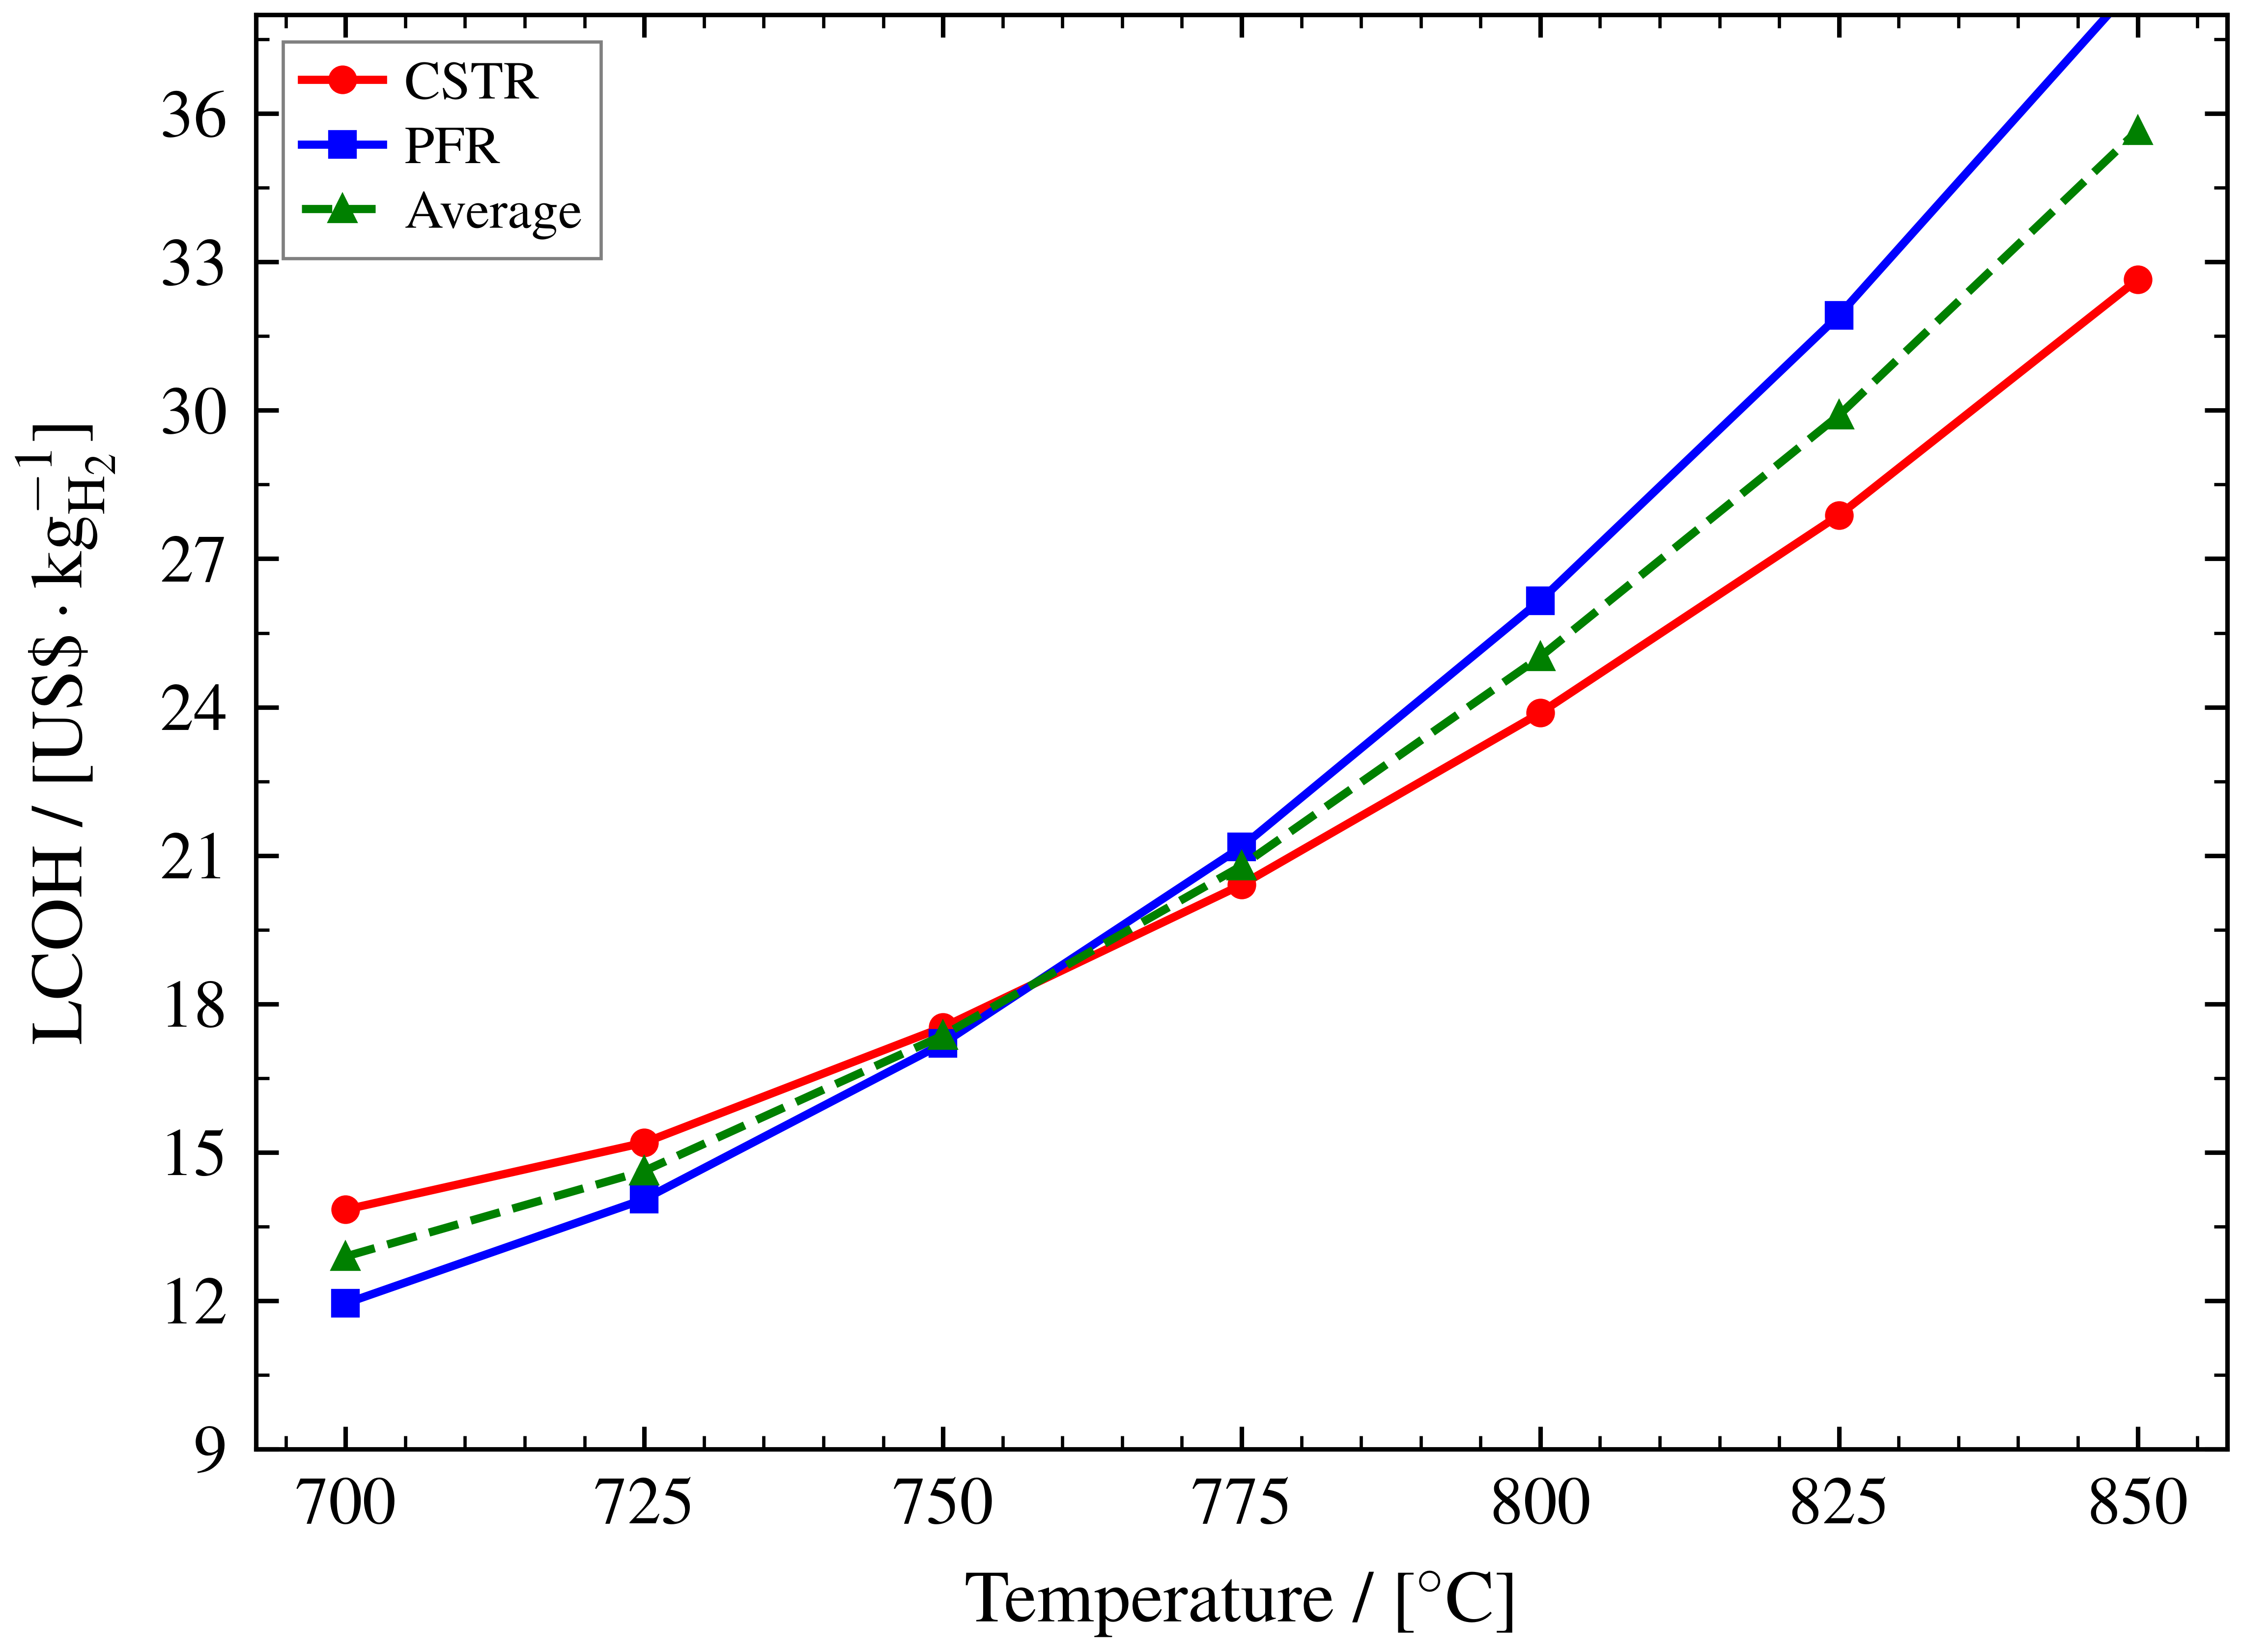


LCOH VS TEMPERATURE
  Temperature [°C]      CSTR [$/kg H2]       PFR [$/kg H2]     Average [$/kg H2]
--------------------------------------------------------------------------------------
            700.00           13.839924           11.943553             12.891738
            725.00           15.194163           14.051020             14.622592
            750.00           17.526539           17.198604             17.362571
            775.00           20.408463           21.174214             20.791339
            800.00           23.883334           26.154263             25.018798
            825.00           27.880660           31.922944             29.901802
            850.00           32.644747           38.670141             35.657444

TEMPERATURES:
[700. 725. 750. 775. 800. 825. 850.]

LCOH CSTR:
[13.83992374 15.19416337 17.52653906 20.40846309 23.88333427 27.88065977
 32.64474674]

LCOH PFR:
[11.94355258 14.05101999 17.19860385 21.17421449 26.15426271 31.92294436
 38.67014

In [22]:
# LCOH VS TEMPERATURE

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import scienceplots
from matplotlib.ticker import MultipleLocator
from pathlib import Path


plt.style.use(["science", "ieee"])

tick_font = 16.5
axis_label_font = 18.0
legend_font = 13.2

mpl.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Times"],
    "font.size": tick_font,
    "axes.labelsize": axis_label_font,
    "xtick.labelsize": tick_font,
    "ytick.labelsize": tick_font,
    "legend.fontsize": legend_font,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "text.color": "black",
    "axes.labelcolor": "black",
    "axes.edgecolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "axes.grid": False,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

#Data
temperatures = np.asarray(temperatures, dtype=float)
lcoh_values_CSTR = np.asarray(lcoh_values_CSTR, dtype=float)
lcoh_values_PFR = np.asarray(lcoh_values_PFR, dtype=float)

lcoh_values_mean = (lcoh_values_CSTR + lcoh_values_PFR) / 2.0

#Figure
fig, ax = plt.subplots(figsize=(8, 6))

#CSTR
ax.plot(
    temperatures, lcoh_values_CSTR,
    '-o', color='red', linewidth=2.0,
    markersize=6, label='CSTR'
)

#PFR
ax.plot(
    temperatures, lcoh_values_PFR,
    '-s', color='blue', linewidth=2.0,
    markersize=6, label='PFR'
)

#Average
ax.plot(
    temperatures, lcoh_values_mean,
    '--^', color='green', linewidth=2.0,
    markersize=6, label='Average'
)

ax.set_xlabel(
    r"Temperature / [$^\circ$C]",
    fontsize=axis_label_font,
    labelpad=8
)

ax.set_ylabel(
    r"LCOH / [US\$\,$\cdot$\,kg$_{\mathrm{H}_2}^{-1}$]",
    fontsize=axis_label_font,
    labelpad=11
)

# X axis
ax.xaxis.set_major_locator(MultipleLocator(25))
ax.xaxis.set_minor_locator(MultipleLocator(5))

# Y axis
ax.set_ylim(9, 38)
ax.yaxis.set_major_locator(MultipleLocator(3))
ax.yaxis.set_minor_locator(MultipleLocator(1.5))

ax.tick_params(
    axis="x", which="major", direction="in",
    top=True, bottom=True, labelsize=tick_font,
    colors="black", length=5.5, width=1.1, pad=7
)

ax.tick_params(
    axis="y", which="major", direction="in",
    left=True, right=True, labelsize=tick_font,
    colors="black", length=5.5, width=1.1, pad=7
)

ax.tick_params(
    axis="x", which="minor", direction="in",
    top=True, bottom=True, colors="black",
    length=3.2, width=0.8
)

ax.tick_params(
    axis="y", which="minor", direction="in",
    left=True, right=True, colors="black",
    length=3.2, width=0.8
)

ax.grid(False)

for spine in ax.spines.values():
    spine.set_color("black")
    spine.set_linewidth(1.1)


legend = ax.legend(
    loc="best",
    fontsize=legend_font,
    frameon=True,
    fancybox=False,
    framealpha=1.0,
    facecolor="white",
    edgecolor="0.50",
    handlelength=1.5,
    handletextpad=0.4,
    borderpad=0.35,
    labelspacing=0.28
)

legend.get_frame().set_linewidth(0.8)

fig.tight_layout()

fig.savefig("LCOH_vs_temperature.pdf",
    format="pdf",
    bbox_inches="tight"
)

plt.show()

#Print values
print()
print("LCOH VS TEMPERATURE")
print("=" * 86)

print(
    f"{'Temperature [°C]':>18}"
    f"{'CSTR [$/kg H2]':>20}"
    f"{'PFR [$/kg H2]':>20}"
    f"{'Average [$/kg H2]':>22}"
)

print("-" * 86)

for temperature, lcoh_cstr, lcoh_pfr, lcoh_average in zip(
    temperatures,
    lcoh_values_CSTR,
    lcoh_values_PFR,
    lcoh_values_mean
):
    print(
        f"{temperature:>18.2f}"
        f"{lcoh_cstr:>20.6f}"
        f"{lcoh_pfr:>20.6f}"
        f"{lcoh_average:>22.6f}"
    )

print("=" * 86)

print("\nTEMPERATURES:")
print(temperatures)

print("\nLCOH CSTR:")
print(lcoh_values_CSTR)

print("\nLCOH PFR:")
print(lcoh_values_PFR)

print("\nLCOH AVERAGE:")
print(lcoh_values_mean)

In [23]:
# Save LCOH vs Temperature in JSON
import json
from pathlib import Path

# Find project root
try:
    start_dir = Path(__file__).resolve().parent
except NameError:
    start_dir = Path.cwd()

project_root = next(
    (p for p in [start_dir, *start_dir.parents]
     if all((p / folder).is_dir() for folder in ["FeMP", "ACMP", "NiMP"])),
    None
)

if project_root is None:
    raise FileNotFoundError("Project root not found.")

# Output directory
results_dir = project_root / "FeMP" / "Results_TEA"
results_dir.mkdir(parents=True, exist_ok=True)

file_lcoh_temperature = results_dir / "LCOH_temperature.json"

# LCOH at different solid carbon selling prices (baseline price: 1.5 US$/kg)
import numpy as np
from copy import deepcopy

carbon_prices = [0.5, 1.5, 2.5]  # US$/kg


def lcoh_at_carbon_price(plant, carbon_price):
    """LCOH of a copy of the plant, with only the carbon selling price changed."""
    plant = deepcopy(plant)
    plant.plant_products["carbon"]["price"] = carbon_price
    return float(np.asarray(plant.calculate_levelized_cost(print_results=False)).item())


# Average of PFR and CSTR, for every temperature, at every carbon price
lcoh_by_carbon_price = {
    str(price): [
        (lcoh_at_carbon_price(pfr, price) + lcoh_at_carbon_price(cstr, price)) / 2
        for pfr, cstr in zip(plant_values_PFR, plant_values_CSTR)
    ]
    for price in carbon_prices
}

# Prepare JSON results
lcoh_temperature_results = {
    "temperature": [float(value) for value in temperatures],
    "lcoh_average": [float(value) for value in lcoh_values_mean],
    # keys are carbon prices in US$/kg; each list follows "temperature"
    "lcoh_average_by_carbon_price": lcoh_by_carbon_price,
}

# Save JSON
with open(file_lcoh_temperature, "w") as f:
    json.dump(lcoh_temperature_results, f, indent=4)

print(f"JSON saved in: {file_lcoh_temperature.resolve()}")

JSON saved in: C:\Users\pbtamarona\OneDrive - Delft University of Technology\Documents\github-pbtamarona\catalytic_mp\CatalyticMethanePyrolysis\FeMP\Results_TEA\LCOH_temperature.json


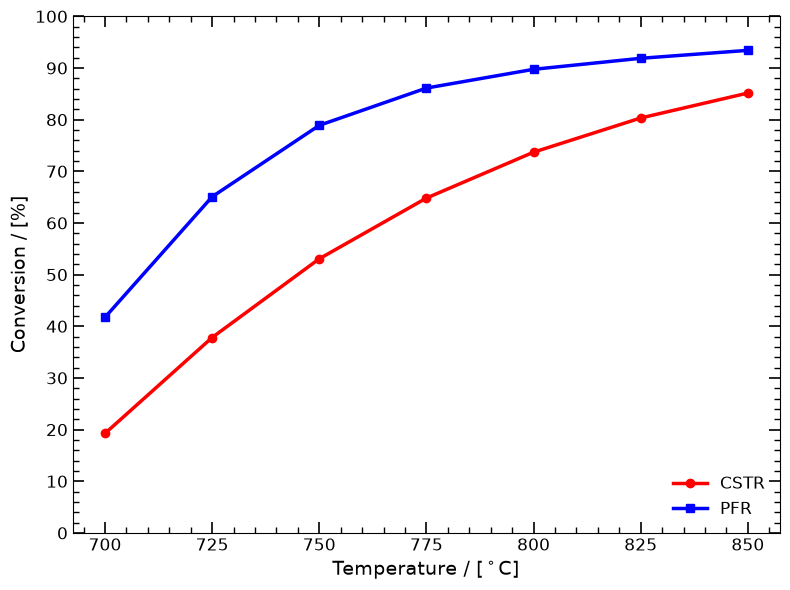

In [24]:
# CONVERSION PLOT vs TEMPERATURE

import json
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib.ticker import MultipleLocator

plt.style.use("default")


fig, ax = plt.subplots(figsize=(8, 6))

#CSTR Curve
ax.plot(
    temperatures,
    conversion_CSTR,
    "-o",
    color="red",
    linewidth=2.5,
    markersize=6,
    label="CSTR"
)

#PFR Curve
ax.plot(
    temperatures,
    conversion_PFR,
    "-s",
    color="blue",
    linewidth=2.5,
    markersize=6,
    label="PFR"
)

ax.set_xlabel(
    r"Temperature / [$^\circ$C]",
    fontsize=14
)

ax.set_ylabel(
    r"Conversion / [%]",
    fontsize=14
)

ax.xaxis.set_major_locator(
    MultipleLocator(25)
)

ax.xaxis.set_minor_locator(
    MultipleLocator(5)
)

ax.set_ylim(0, 100)

ax.yaxis.set_major_locator(
    MultipleLocator(10)
)

ax.yaxis.set_minor_locator(
    MultipleLocator(2)
)

ax.tick_params(
    which="major",
    direction="in",
    top=True,
    right=True,
    length=8,
    width=1.2,
    labelsize=12
)

ax.tick_params(
    which="minor",
    direction="in",
    top=True,
    right=True,
    length=4,
    width=1.0
)

ax.legend(
    frameon=False,
    fontsize=12,
    loc="lower right"
)

plt.tight_layout()

plt.show()


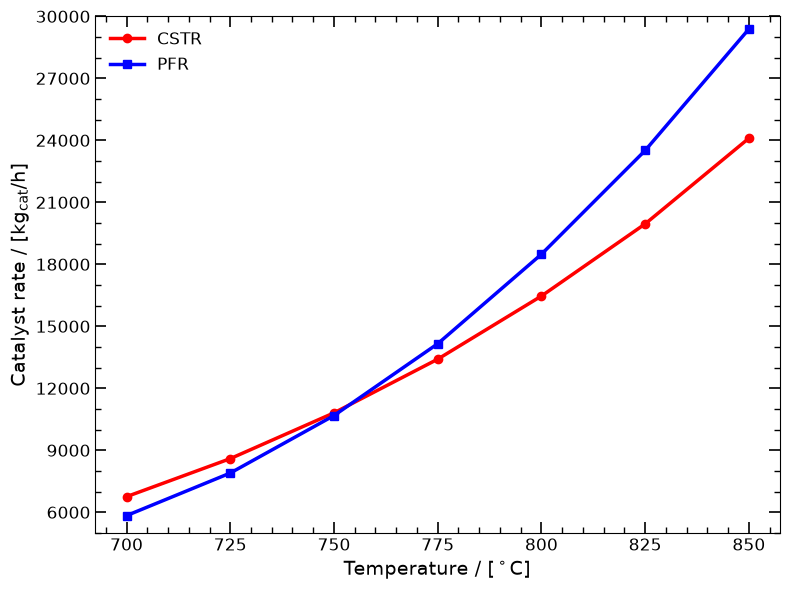

In [25]:
# CATALYST RATE PLOT vs TEMPERATURE
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

plt.style.use('default')


fig, ax = plt.subplots(figsize=(8, 6))

# Curve CSTR
ax.plot(
    temperatures,
    catrate_CSTR,
    '-o',
    color='red',
    linewidth=2.5,
    markersize=6,
    label='CSTR'
)

# Curve PFR
ax.plot(
    temperatures,
    catrate_PFR,
    '-s',
    color='blue',
    linewidth=2.5,
    markersize=6,
    label='PFR'
)

ax.set_xlabel(
    r"Temperature / [$^\circ$C]",
    fontsize=14
)

ax.set_ylabel(
    r"Catalyst rate / [kg$_{\mathrm{cat}}$/h]",
    fontsize=14
)

#X Axis
ax.xaxis.set_major_locator(MultipleLocator(25))
ax.xaxis.set_minor_locator(MultipleLocator(5))

#Y Axis
ax.set_ylim(5000, 30000)
ax.yaxis.set_major_locator(MultipleLocator(3000))
ax.yaxis.set_minor_locator(MultipleLocator(1000))


ax.tick_params(
    which='major',
    direction='in',
    top=True,
    right=True,
    length=8,
    width=1.2,
    labelsize=12
)

ax.tick_params(
    which='minor',
    direction='in',
    top=True,
    right=True,
    length=4,
    width=1.0
)

ax.legend(
    frameon=False,
    fontsize=12
)

plt.tight_layout()
plt.show()

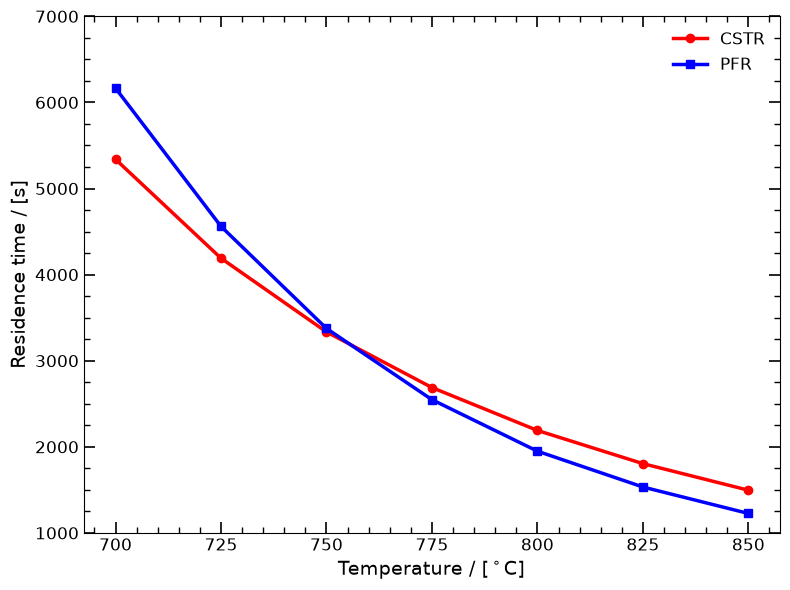

In [26]:
# RESIDENCE TIME PLOT vs TEMPERATURE
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator


plt.style.use('default')

fig, ax = plt.subplots(figsize=(8, 6))

# Curve CSTR
ax.plot(
    temperatures,
    residence_time_CSTR,
    '-o',
    color='red',
    linewidth=2.5,
    markersize=6,
    label='CSTR'
)

# Curve PFR
ax.plot(
    temperatures,
    residence_time_PFR,
    '-s',
    color='blue',
    linewidth=2.5,
    markersize=6,
    label='PFR'
)

ax.set_xlabel(r"Temperature / [$^\circ$C]", fontsize=14)
ax.set_ylabel(r"Residence time / [s]", fontsize=14)

#X Axis
ax.xaxis.set_major_locator(MultipleLocator(25))
ax.xaxis.set_minor_locator(MultipleLocator(5))

# Y Axis
ax.set_ylim(1000, 7000)
ax.yaxis.set_major_locator(MultipleLocator(1000))
ax.yaxis.set_minor_locator(MultipleLocator(250))


ax.tick_params(
    which='major',
    direction='in',
    top=True,
    right=True,
    length=8,
    width=1.2,
    labelsize=12
)

ax.tick_params(
    which='minor',
    direction='in',
    top=True,
    right=True,
    length=4,
    width=1.0
)


ax.legend(frameon=False, fontsize=12)

plt.tight_layout()
plt.show()

In [27]:
# LCOH SWEEPS AT T = 725 °C: CATALYST AMOUNT AND DEACTIVATION FACTOR
# Each sweep keeps its own results, so these plots don't depend on which
# sweep the PFR/CSTR loop cells above last ran (they run the temperature sweep).
import numpy as np


def lcoh_sweep(csv_files_PFR, csv_files_CSTR):
    """Run the PFR and CSTR TEA for every case in a sweep.

    Both dicts map the swept value (e.g. catalyst amount) to a simulation CSV.
    Returns the swept values and the LCOH of each reactor, in the same order.
    """
    if list(csv_files_PFR) != list(csv_files_CSTR):
        raise ValueError("PFR and CSTR sweeps must cover the same values.")

    return {
        "values": np.asarray(list(csv_files_PFR), dtype=float),
        "lcoh_PFR": np.asarray(
            [run_tea_pfr(path)["lcoh_pfr"] for path in csv_files_PFR.values()],
            dtype=float,
        ),
        "lcoh_CSTR": np.asarray(
            [run_tea_cstr(path)["lcoh_cstr"] for path in csv_files_CSTR.values()],
            dtype=float,
        ),
    }


# Fixed T (725 °C) and a (0.2)
sweep_catalyst_amount = lcoh_sweep(
    csv_files_PFR_T725_DA02_Wchange, csv_files_CSTR_T725_DA02_Wchange
)

# Fixed T (725 °C) and w (10000 kg)
sweep_deactivation = lcoh_sweep(
    csv_files_PFR_T725_W10000_DAchange, csv_files_CSTR_T725_W10000_DAchange
)

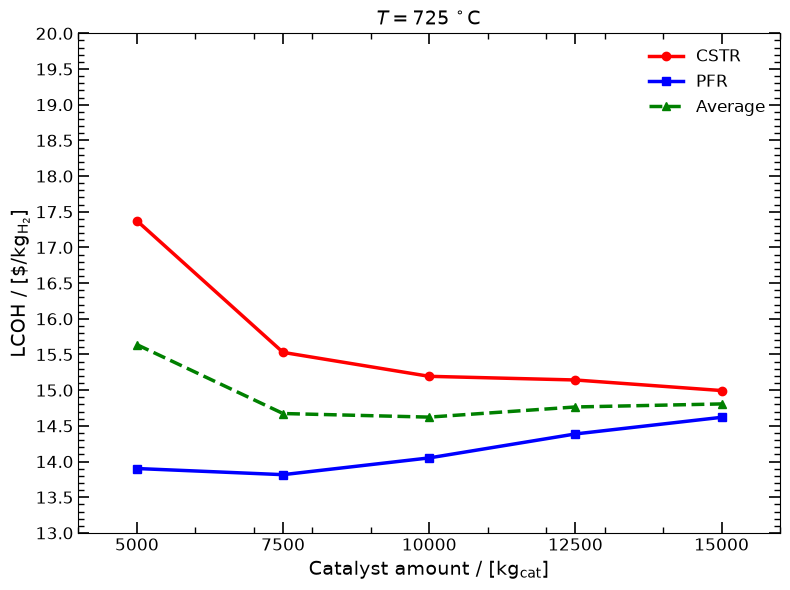

In [28]:
# LCOH VS CATALYST AMOUNT
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

plt.style.use('default')


catalyst_amounts_array = sweep_catalyst_amount["values"]

lcoh_catamount_CSTR_array = sweep_catalyst_amount["lcoh_CSTR"]
lcoh_catamount_PFR_array = sweep_catalyst_amount["lcoh_PFR"]

#Average
lcoh_catamount_mean = (
    lcoh_catamount_CSTR_array
    + lcoh_catamount_PFR_array
) / 2

fig, ax = plt.subplots(figsize=(8, 6))

# Curve CSTR
ax.plot(
    catalyst_amounts_array,
    lcoh_catamount_CSTR_array,
    '-o',
    color='red',
    linewidth=2.5,
    markersize=6,
    label='CSTR'
)

# Curve PFR
ax.plot(
    catalyst_amounts_array,
    lcoh_catamount_PFR_array,
    '-s',
    color='blue',
    linewidth=2.5,
    markersize=6,
    label='PFR'
)

# Curve average
ax.plot(
    catalyst_amounts_array,
    lcoh_catamount_mean,
    '--^',
    color='green',
    linewidth=2.5,
    markersize=6,
    label='Average'
)


ax.set_xlabel(
    r"Catalyst amount / [kg$_{\mathrm{cat}}$]",
    fontsize=14
)

ax.set_ylabel(
    r"LCOH / [\$/kg$_{\mathrm{H}_2}$]",
    fontsize=14
)

ax.set_title(
    r"$T = 725\,^\circ$C",
    fontsize=14
)

# X Axis
ax.set_xlim(4000, 16000)
ax.set_xticks(catalyst_amounts_array)
ax.xaxis.set_minor_locator(MultipleLocator(1000))

# Y Axis
ax.set_ylim(13, 20)
ax.yaxis.set_major_locator(MultipleLocator(0.5))
ax.yaxis.set_minor_locator(MultipleLocator(0.1))


ax.tick_params(
    which='major',
    direction='in',
    top=True,
    right=True,
    length=8,
    width=1.2,
    labelsize=12
)

ax.tick_params(
    which='minor',
    direction='in',
    top=True,
    right=True,
    length=4,
    width=1.0
)


ax.legend(
    frameon=False,
    fontsize=12
)

plt.tight_layout()
plt.show()

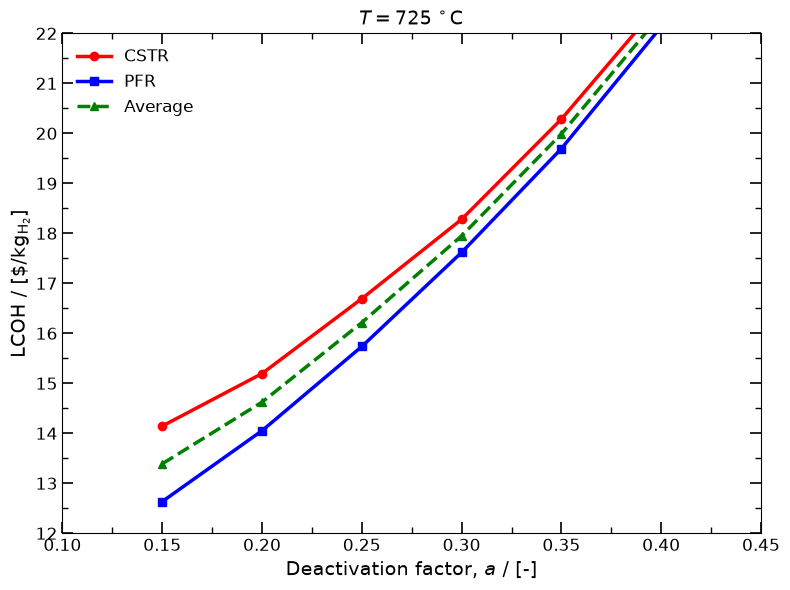

In [29]:
# LCOH VS DEACTIVATION FACTOR
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator


plt.style.use('default')


deactivation_factors_array = sweep_deactivation["values"]

lcoh_deactivation_CSTR_array = sweep_deactivation["lcoh_CSTR"]
lcoh_deactivation_PFR_array = sweep_deactivation["lcoh_PFR"]

# Average
lcoh_deactivation_mean = (
    lcoh_deactivation_CSTR_array
    + lcoh_deactivation_PFR_array
) / 2

fig, ax = plt.subplots(figsize=(8, 6))

# Curve CSTR
ax.plot(
    deactivation_factors_array,
    lcoh_deactivation_CSTR_array,
    '-o',
    color='red',
    linewidth=2.5,
    markersize=6,
    label='CSTR'
)

# Curve PFR
ax.plot(
    deactivation_factors_array,
    lcoh_deactivation_PFR_array,
    '-s',
    color='blue',
    linewidth=2.5,
    markersize=6,
    label='PFR'
)

# Curve average
ax.plot(
    deactivation_factors_array,
    lcoh_deactivation_mean,
    '--^',
    color='green',
    linewidth=2.5,
    markersize=6,
    label='Average'
)

ax.set_xlabel(
    r"Deactivation factor, $a$ / [-]",
    fontsize=14
)

ax.set_ylabel(
    r"LCOH / [\$/kg$_{\mathrm{H}_2}$]",
    fontsize=14
)

ax.set_title(
    r"$T = 725\,^\circ$C",
    fontsize=14
)

# X Axis
ax.set_xticks(deactivation_factors_array)

ax.set_xlim(0.1, 0.45)

ax.xaxis.set_major_locator(MultipleLocator(0.05))
ax.xaxis.set_minor_locator(MultipleLocator(0.025))

# Y Axis
ax.set_ylim(12, 22)
ax.yaxis.set_major_locator(MultipleLocator(1))
ax.yaxis.set_minor_locator(MultipleLocator(0.5))

ax.tick_params(
    which='major',
    direction='in',
    top=True,
    right=True,
    length=8,
    width=1.2,
    labelsize=12
)

ax.tick_params(
    which='minor',
    direction='in',
    top=True,
    right=True,
    length=4,
    width=1.0
)

ax.legend(
    frameon=False,
    fontsize=12
)

plt.tight_layout()
plt.show()

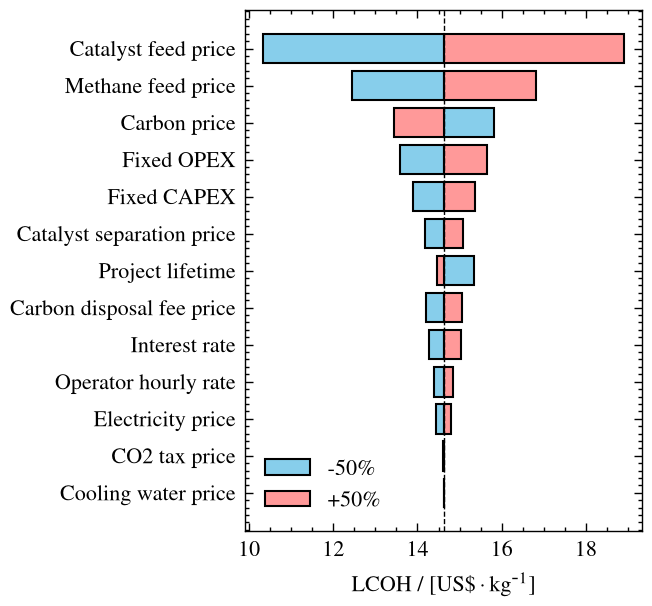

In [30]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from pathlib import Path

#Tornado Plot

tornado_PFR = tornado_data(plant=plant_values_PFR[idx], plus_minus_value=0.5, metric="LCOP")
tornado_CSTR = tornado_data(plant=plant_values_CSTR[idx], plus_minus_value=0.5, metric="LCOP")

#Average

def average_tornado_data(data_pfr, data_cstr):

    pfr_results = {
        factor: {"low": low, "high": high, "label": label}
        for factor, low, high, label in zip(
            data_pfr["factors"], data_pfr["lows"], data_pfr["highs"], data_pfr["labels"]
        )
    }

    cstr_results = {
        factor: {"low": low, "high": high, "label": label}
        for factor, low, high, label in zip(
            data_cstr["factors"], data_cstr["lows"], data_cstr["highs"], data_cstr["labels"]
        )
    }

    if set(pfr_results) != set(cstr_results):
        raise ValueError("PFR and CSTR do not contain the same sensitivity parameters.")

    averaged_results = []

    for factor in pfr_results:
        average_low = (pfr_results[factor]["low"] + cstr_results[factor]["low"]) / 2
        average_high = (pfr_results[factor]["high"] + cstr_results[factor]["high"]) / 2
        label = pfr_results[factor]["label"]
        averaged_results.append((factor, average_low, average_high, label))

    averaged_results.sort(key=lambda result: abs(result[2] - result[1]))

    return {
        "factors": [result[0] for result in averaged_results],
        "lows": np.array([result[1] for result in averaged_results]),
        "highs": np.array([result[2] for result in averaged_results]),
        "labels": [result[3] for result in averaged_results],
        "base_value": (data_pfr["base_value"] + data_cstr["base_value"]) / 2,
        "plus_minus_value": data_pfr["plus_minus_value"],
        "metric": "LCOP",
        "xlabel": r"LCOH / [US\$\,$\cdot$\,kg$^{\mbox{-}1}$]"
    }

tornado_average = average_tornado_data(tornado_PFR, tornado_CSTR)

# The plot cells above call plt.style.use("default"), which switches LaTeX off.
# The \mbox in the LCOH label needs LaTeX, so restore the OpenPyTEA style first.
plt.style.use(["science", "ieee"])
mpl.rcParams.update({"text.usetex": True, "figure.dpi": 200, "savefig.dpi": 600})

fig, ax = plot_tornado(tornado_average)

ax.set_xlabel(r"LCOH / [US\$\,$\cdot$\,kg$^{\mbox{-}1}$]")
ax.set_title("")

fig.savefig("LCOH_tornado.pdf", format="pdf")

plt.show()

Monte Carlo:   0%|          | 0/100 [00:00<?, ?it/s]

Monte Carlo:   1%|          | 1/100 [00:00<00:57,  1.73it/s]

Monte Carlo:   2%|▏         | 2/100 [00:01<00:48,  2.00it/s]

Monte Carlo:   3%|▎         | 3/100 [00:01<00:41,  2.31it/s]

Monte Carlo:   4%|▍         | 4/100 [00:01<00:41,  2.31it/s]

Monte Carlo:   5%|▌         | 5/100 [00:02<00:37,  2.57it/s]

... (194 outputs left out)

Monte Carlo:  98%|█████████▊| 98/100 [00:45<00:01,  1.84it/s]

Monte Carlo:  99%|█████████▉| 99/100 [00:45<00:00,  1.90it/s]

Monte Carlo: 100%|██████████| 100/100 [00:46<00:00,  1.88it/s]

Monte Carlo: 100%|██████████| 100/100 [00:46<00:00,  2.17it/s]

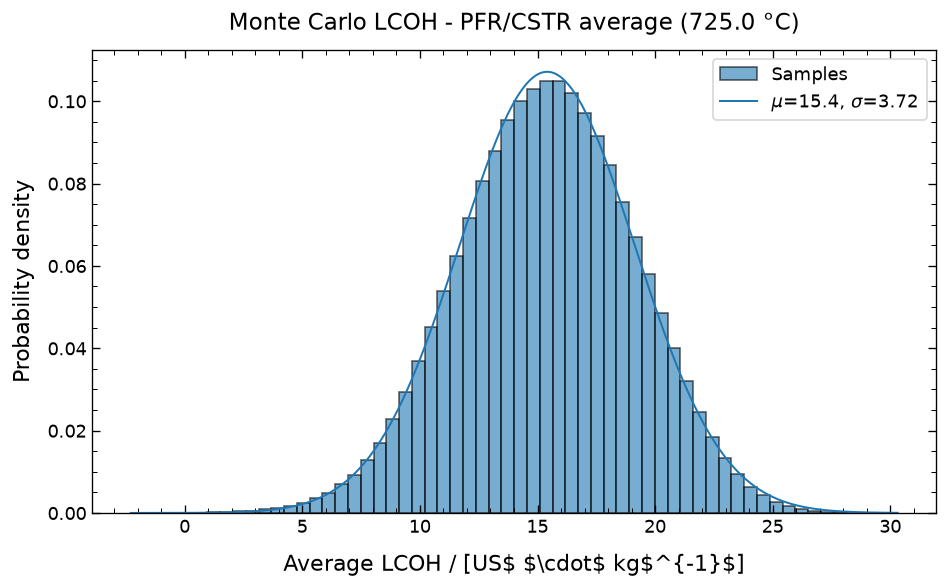

In [31]:
# Monte Carlo simulations on economic variables

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from copy import deepcopy
from scipy.optimize import brentq
from scipy.stats import norm, truncnorm, spearmanr
from openpytea.analysis import make_distribution
from openpytea.analysis import monte_carlo
from openpytea.plotting import plot_monte_carlo

num_samples, batch_size, num_bins, seed = 1_000_000, 10_000, 60, 12345

# New economic distributions

# Separation efficiency: fraction of iron removed: lognormal (OpenPyTEA dist_id 2)
sep_eff, sep_eff_std, sep_eff_max, sep_eff_min = 0.85, 0.05, 0.90, 0.30

# Carbon selling price ($/kg of carbon-rich mixture): lognormal (OpenPyTEA dist_id 2)
carbon_price, carbon_std, carbon_max, carbon_min = 1.5, 1.5, 6, 0.5

# Carbon disposal fee ($/kg of disposed mixture): lognormal (OpenPyTEA dist_id 2)
disposal_price, disposal_std, disposal_max, disposal_min = 0.75, 0.75, 2, 0.25

# Separation cost ($/kg of catalyst removed); truncated normal, rises with separation efficiency
separation_cost, separation_cost_std, separation_cost_max, separation_cost_min = 0.5, 0.4, 2.5, 0.1

# Fraction of carbon-rich mixture sold: independent lognormal, tail towards low values
sale_fraction, sale_fraction_std, sale_fraction_max, sale_fraction_min = 0.50, 0.2, 1.0, 0.0

# Set plant and solid streams

temperature = temperatures[idx]

def read_solid_flows(csv_path):
    df = pd.read_csv(csv_path)
    carbon_flow = float(df["C Prod [kg/h]"].iloc[0])
    iron_flow = float(df["Cat Rate [kg/h]"].iloc[0])

    if not np.isfinite(carbon_flow) or not np.isfinite(iron_flow) or carbon_flow <= 0 or iron_flow < 0:
        raise ValueError(f"Invalid solid flow rates in {csv_path}")

    return carbon_flow, iron_flow

carbon_PFR, iron_PFR = read_solid_flows(csv_files_PFR_Tchange_DA02_W10000[temperature])
carbon_CSTR, iron_CSTR = read_solid_flows(csv_files_CSTR_Tchange_DA02_W10000[temperature])


def make_updated_plant(plant, carbon_flow, iron_flow):
    p = deepcopy(plant)

    rich_flow_baseline = carbon_flow + (1-sep_eff)*iron_flow

    p.plant_products["carbon"].update({
        "production": rich_flow_baseline*sale_fraction*24,
        "price": carbon_price, "std": carbon_std,
        "max": carbon_max, "min": carbon_min
    })

    p.variable_opex_inputs["carbon_disposal_fee"].update({
        "consumption": rich_flow_baseline*(1-sale_fraction)*24,
        "price": disposal_price, "std": disposal_std,
        "max": disposal_max, "min": disposal_min
    })

    # Separation cost on the catalyst removed (MC mean separation efficiency)
    p.variable_opex_inputs["catalyst_separation"]["consumption"] = sep_eff*iron_flow*24

    return p

plant_PFR_new = make_updated_plant(plant_values_PFR[idx], carbon_PFR, iron_PFR)
plant_CSTR_new = make_updated_plant(plant_values_CSTR[idx], carbon_CSTR, iron_CSTR)

#Sampling

base_mc_PFR = monte_carlo(
    plant_PFR_new, num_samples=num_samples,
    batch_size=batch_size, random_seed=seed
)

base_mc_CSTR = monte_carlo(
    plant_CSTR_new, num_samples=num_samples,
    batch_size=batch_size, random_seed=seed
)

# Verify that PFR and CSTR use identical economic samples
shared_economic_inputs = [
    "Fixed capital factor", "Fixed opex factor",
    "Operator hourly rate", "Project lifetime", "Interest rate",
    "Electricity price", "Methane Feed price", "Catalyst Feed price",
    "Cooling Water price", "Co2 Tax price"
]

for key in shared_economic_inputs:
    if key not in base_mc_PFR["inputs"] or key not in base_mc_CSTR["inputs"]:
        raise KeyError(f"Missing Monte Carlo input: {key}")

    if not np.array_equal(base_mc_PFR["inputs"][key], base_mc_CSTR["inputs"][key], equal_nan=True):
        raise ValueError(f"PFR/CSTR economic draws differ for '{key}'.")


# Generate distributions

def truncated_normal_quantile(u, mu, sigma, low, high):
    a, b = (low-mu)/sigma, (high-mu)/sigma
    return truncnorm.ppf(u, a, b, loc=mu, scale=sigma)

def lognormal_quantile(u, mean, std, minimum, maximum, tail="high"):
    """Quantiles ``u`` of OpenPyTEA's lognormal (dist_id 2) truncated to [minimum, maximum].

    tail="high": long tail towards the maximum (standard lognormal).
    tail="low":  long tail towards the minimum (lognormal mirrored at the maximum,
                 x = maximum - Y). Quantiles still increase with ``u``.
    sigma (of ln x) is matched to ``std``; mu is tuned so that the mean of the
    truncated distribution equals ``mean``.
    """
    if tail == "low":
        return maximum - lognormal_quantile(1 - np.asarray(u), maximum - mean, std,
                                            0.0, maximum - minimum, tail="high")

    sigma = np.sqrt(np.log(1 + (std / mean) ** 2))
    log_low = np.log(minimum) if minimum > 0 else -np.inf
    log_high = np.log(maximum)

    def truncated_mean_gap(mu):
        # E[x | minimum <= x <= maximum] - mean, closed form for a lognormal
        a, b = (log_low - mu) / sigma, (log_high - mu) / sigma
        mass = norm.cdf(b) - norm.cdf(a)
        return np.exp(mu + sigma**2 / 2) * (norm.cdf(b - sigma) - norm.cdf(a - sigma)) / mass - mean

    # Bracket: low mu -> truncated mean near the minimum; high mu -> near the maximum
    mu = brentq(truncated_mean_gap, np.log(mean) - 5 * sigma - 1, log_high + 3 * sigma)
    dist = make_distribution(2, loc=mu, scale=sigma)
    low, high = dist.cdf(minimum), dist.cdf(maximum)
    return dist.ppf(low + np.asarray(u) * (high - low))

rng = np.random.default_rng(seed + 1)

u = np.clip(rng.random(num_samples), 1e-12, 1-1e-12)

# Linked: separation efficiency, carbon price and separation cost rise together (purity),
# disposal fee moves the opposite way
separation_efficiency = lognormal_quantile(
    u, sep_eff, sep_eff_std, sep_eff_min, sep_eff_max
)

carbon_selling_price = lognormal_quantile(
    u, carbon_price, carbon_std, carbon_min, carbon_max
)

carbon_disposal_fee = lognormal_quantile(
    1-u, disposal_price, disposal_std, disposal_min, disposal_max
)

# Independent random percentiles for the fraction sold
u_sale = np.clip(rng.random(num_samples), 1e-12, 1-1e-12)

carbon_sale_fraction = lognormal_quantile(
    u_sale, sale_fraction, sale_fraction_std,
    sale_fraction_min, sale_fraction_max, tail="low"
)

# Separation cost: same percentiles as separation efficiency (higher purity -> higher cost)
separation_cost_samples = truncated_normal_quantile(
    u, separation_cost, separation_cost_std,
    separation_cost_min, separation_cost_max
)

# Material balances

def material_balance(carbon_flow, iron_flow):

    # Residual iron after separation
    iron_residual = (1-separation_efficiency)*iron_flow
    iron_removed = iron_flow - iron_residual

    # Carbon-rich mixture
    carbon_rich = carbon_flow + iron_residual

    # Carbon purity
    purity = carbon_flow/carbon_rich

    # Independent fraction sold
    sold = carbon_sale_fraction*carbon_rich
    disposed = (1-carbon_sale_fraction)*carbon_rich

    np.testing.assert_allclose(sold + disposed, carbon_rich)

    return {
        "purity": purity,
        "iron_residual": iron_residual,
        "iron_removed": iron_removed,
        "carbon_rich": carbon_rich,
        "sold": sold,
        "disposed": disposed
    }

streams_PFR = material_balance(carbon_PFR, iron_PFR)
streams_CSTR = material_balance(carbon_CSTR, iron_CSTR)


# Recalculate economics

def evaluate_separation_mc(plant, base_mc, streams, name):

    inputs = {key: np.asarray(value).copy() for key, value in base_mc["inputs"].items()}

    # Updated carbon prices and mass flows
    inputs["Carbon product price"] = carbon_selling_price.copy()
    inputs["Carbon Disposal Fee price"] = carbon_disposal_fee.copy()
    inputs["Carbon production"] = streams["sold"]*24
    inputs["Carbon Disposal Fee consumption"] = streams["disposed"]*24
    inputs["Catalyst Separation consumption"] = streams["iron_removed"]*24
    inputs["Catalyst Separation price"] = separation_cost_samples.copy()

    # Additional diagnostic inputs
    inputs["Separation efficiency"] = separation_efficiency.copy()
    inputs["Carbon purity"] = streams["purity"].copy()
    inputs["Carbon sale fraction"] = carbon_sale_fraction.copy()
    inputs["Residual iron flow (kg/h)"] = streams["iron_residual"].copy()
    inputs["Carbon-rich flow (kg/h)"] = streams["carbon_rich"].copy()

    lcoh_samples = np.empty(num_samples)

    for start in range(0, num_samples, batch_size):

        end = min(start + batch_size, num_samples)
        s = slice(start, end)
        p = deepcopy(plant)

        # Operator costs
        p.operator_hourly_rate["rate"] = inputs["Operator hourly rate"][s]

        # Project economic assumptions
        changes = {
            "project_lifetime": inputs["Project lifetime"][s],
            "interest_rate": inputs["Interest rate"][s]
        }

        if "Plant utilization" in inputs:
            changes["plant_utilization"] = inputs["Plant utilization"][s]

        if "Tax rate" in inputs:
            changes["tax_rate"] = inputs["Tax rate"][s]

        p.update_configuration(changes)

        # Variable OPEX
        for item in plant.variable_opex_inputs:
            label = item.replace("_", " ").title()
            p.variable_opex_inputs[item]["price"] = inputs[f"{label} price"][s]
            p.variable_opex_inputs[item]["consumption"] = inputs[f"{label} consumption"][s]

        # Product revenues
        for product in plant.plant_products:
            label = product.replace("_", " ").title()

            if f"{label} product price" in inputs:
                p.plant_products[product]["price"] = inputs[f"{label} product price"][s]

            p.plant_products[product]["production"] = inputs[f"{label} production"][s]

        # OpenPyTEA economic calculations
        p.calculate_fixed_capital(fc=inputs["Fixed capital factor"][s])
        p.calculate_variable_opex()
        p.calculate_fixed_opex(fp=inputs["Fixed opex factor"][s])
        p.calculate_cash_flow()
        p.calculate_levelized_cost()

        # Unclipped LCOH: OpenPyTEA floors the LCOP at 0, but negative values
        # (carbon revenue above all costs) are kept here
        disc_capex, disc_opex, disc_side_rev, disc_prod = p._discounted_totals()
        lcoh_samples[s] = np.ravel((disc_capex + disc_opex - disc_side_rev) / disc_prod)

    if not np.all(np.isfinite(lcoh_samples)):
        raise ValueError(f"Non-finite LCOH values in {name}")

    return {
        "name": name,
        "metrics": {"LCOP": lcoh_samples},
        "inputs": inputs,
        "num_samples": num_samples,
        "additional_capex": False,
        "currency": base_mc.get("currency", r"\$")
    }

# New lcoh

mc_results_PFR_sep = evaluate_separation_mc(
    plant_PFR_new, base_mc_PFR, streams_PFR, "PFR - Separation MC"
)

mc_results_CSTR_sep = evaluate_separation_mc(
    plant_CSTR_new, base_mc_CSTR, streams_CSTR, "CSTR - Separation MC"
)

lcoh_mc_average = (
    mc_results_PFR_sep["metrics"]["LCOP"] +
    mc_results_CSTR_sep["metrics"]["LCOP"]
) / 2

mc_results_average_sep = deepcopy(mc_results_PFR_sep)
mc_results_average_sep["name"] = "Average PFR-CSTR - Separation MC"
mc_results_average_sep["metrics"] = {"LCOP": lcoh_mc_average}


#Plot

with plt.style.context("default"):

    fig, ax = plot_monte_carlo(
        mc_results_average_sep,
        metric="LCOP",
        bins=num_bins,
        figsize=(8, 5),
        show=False
    )

    fig.set_dpi(120)
    fig.set_facecolor("white")
    ax.set_facecolor("white")

    ax.set_title(
        f"Monte Carlo LCOH - PFR/CSTR average ({temperatures[idx]} °C)",
        fontsize=14, pad=12
    )

    ax.set_xlabel(r"Average LCOH / [US$ $\cdot$ kg$^{-1}$]", fontsize=13, labelpad=10)
    ax.set_ylabel("Probability density", fontsize=13, labelpad=8)

    ax.tick_params(
        axis="both", which="major", direction="in",
        top=True, right=True, labelsize=11, length=5
    )

    ax.tick_params(
        axis="both", which="minor", direction="in",
        top=True, right=True, length=3
    )

    ax.minorticks_on()

    ax.legend(loc="upper right", fontsize=11, frameon=True)

    fig.tight_layout()
    plt.show()



In [32]:
# Save Monte Carlo results
import json
from pathlib import Path

# Find project root
try:
    start_dir = Path(__file__).resolve().parent
except NameError:
    start_dir = Path.cwd()

project_root = next(
    (p for p in [start_dir, *start_dir.parents]
     if all((p / folder).is_dir() for folder in ["FeMP", "ACMP", "NiMP"])),
    None
)

if project_root is None:
    raise FileNotFoundError("Project root not found.")

# Output directory
results_dir = project_root / "FeMP" / "Results_TEA"
results_dir.mkdir(parents=True, exist_ok=True)

mc_file = results_dir / "LCOH_MonteCarlo.json"

# Prepare Monte Carlo results
mc_export = {
    "name": "Iron",
    "temperature": float(temperatures[idx]),
    "metrics": {
        "LCOP": lcoh_mc_average.tolist()
    },
    # Sampled carbon-related inputs, for plotting their distributions
    "inputs": {
        "Carbon selling price [US$/kg]": carbon_selling_price.tolist(),
        "Carbon disposal fee [US$/kg]": carbon_disposal_fee.tolist(),
        "Carbon fraction sold [-]": carbon_sale_fraction.tolist(),
        "Separation efficiency [-]": separation_efficiency.tolist(),
        "Separation cost [US$/kg]": separation_cost_samples.tolist(),
    }
}

# Save JSON
with open(mc_file, "w") as f:
    json.dump(mc_export, f, indent=4)

print(f"JSON saved in: {mc_file.resolve()}")

JSON saved in: C:\Users\pbtamarona\OneDrive - Delft University of Technology\Documents\github-pbtamarona\catalytic_mp\CatalyticMethanePyrolysis\FeMP\Results_TEA\LCOH_MonteCarlo.json
